<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/main/NEXORA_A03_EN3150.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03 - NEXORA
## Full Combined Code



---
## Part 1 - Data Preparation


<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/main/Data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03- NEXORA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.20.0


In [ ]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [ ]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation


In [ ]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

In [ ]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [              <=>   ] 656.65M  55.5MB/s    in 12s     


In [ ]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

In [ ]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [ ]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Glass', 'Vegetation', 'Cardboard', 'Plastic', 'Miscellaneous Trash', 'Food Organics', 'Textile Trash', 'Metal', 'Paper']


In [ ]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [ ]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

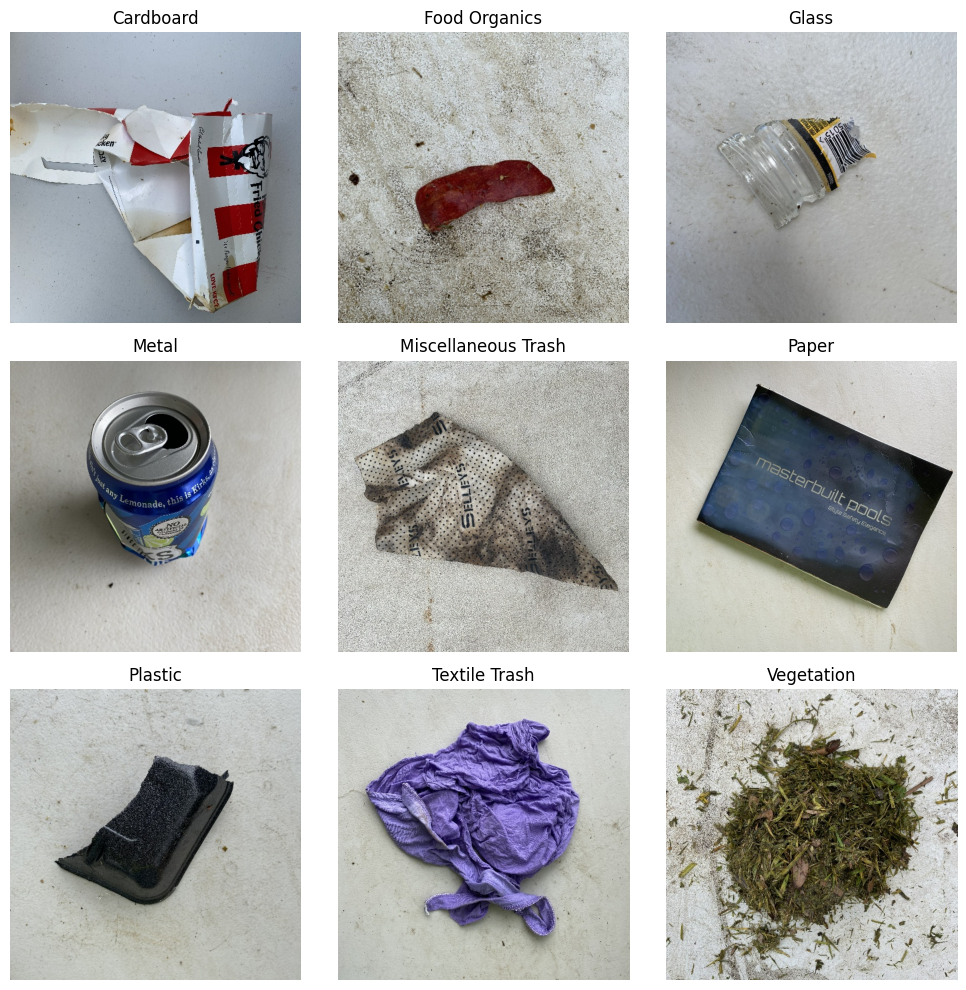

In [ ]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels

In [ ]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

In [ ]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [ ]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [ ]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [ ]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing

In [ ]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [ ]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


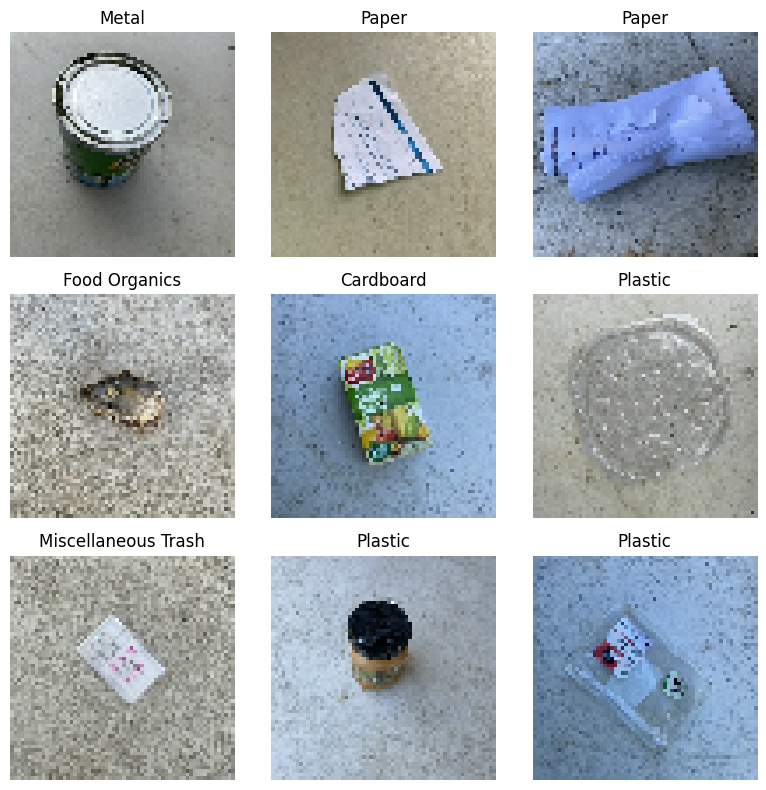

In [ ]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()


---
## Part 2 - Model A


<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/kushen-modelA/Kushen_ModelA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03- NEXORA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [ ]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [ ]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation


In [ ]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

In [ ]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [              <=>   ] 656.65M  38.3MB/s    in 24s     


In [ ]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

In [ ]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [ ]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Food Organics', 'Metal', 'Textile Trash', 'Glass', 'Plastic', 'Cardboard', 'Paper', 'Miscellaneous Trash', 'Vegetation']


In [ ]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [ ]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

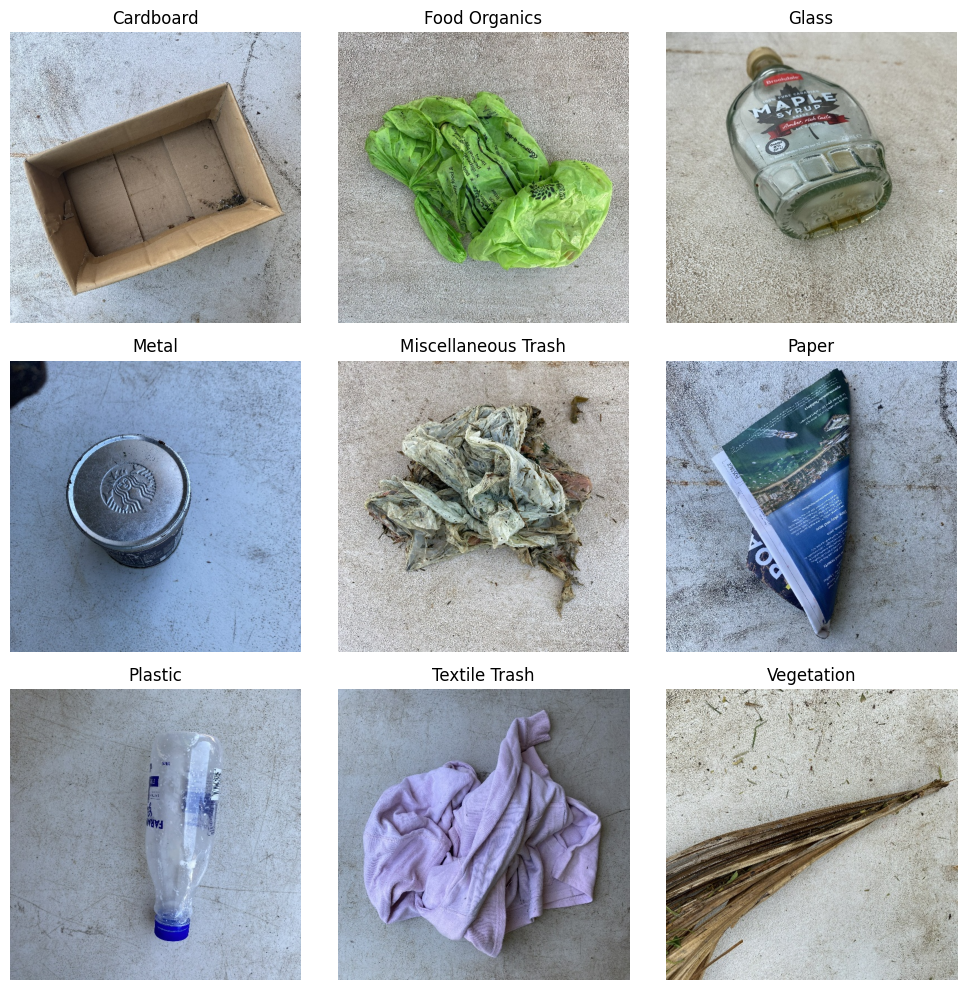

In [ ]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels

In [ ]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

In [ ]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [ ]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [ ]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [ ]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing

In [ ]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [ ]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


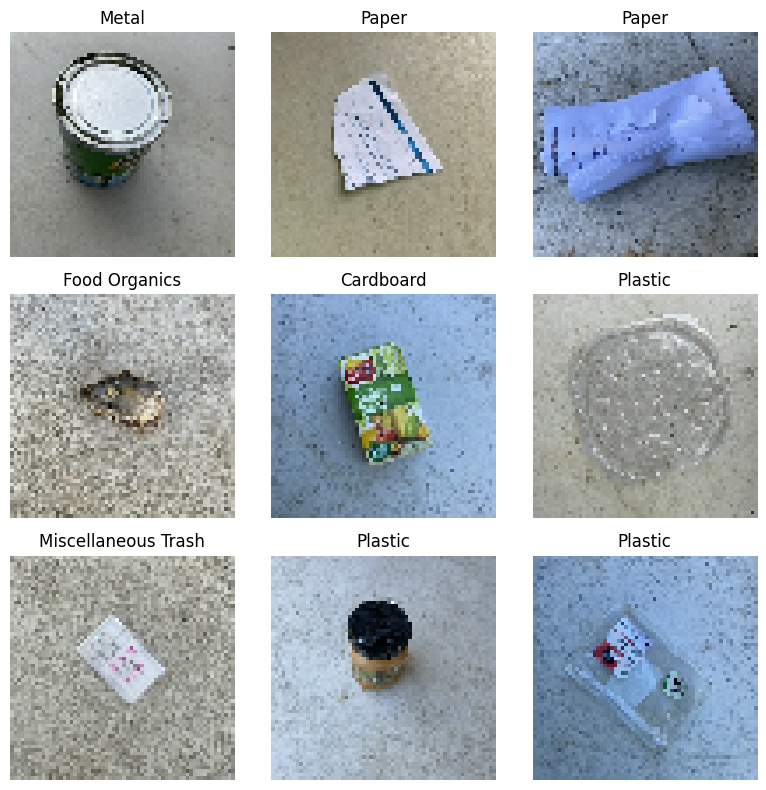

In [ ]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Model A - Standard CNN

In [ ]:
# number of classes in the dataset
num_classes = len(class_names)

print("Number of classes:", num_classes)

Number of classes: 9


In [ ]:
# standard CNN model

model_a = keras.Sequential([

    layers.Input(shape=(image_height, image_width, 3)),

    layers.Conv2D(16, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),

    layers.Dense(64, activation="relu"),

    layers.Dense(num_classes, activation="softmax")
])

In [ ]:
model_a.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       262,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 9)              │           585 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,377 (1.09 MB)

 Trainable params: 286,377 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
total_params = model_a.count_params()

print("Total parameters:", total_params)

Total parameters: 286377


### Model A details

In [ ]:
# check total number of parameters
print("Total parameters:", model_a.count_params())

Total parameters: 286377


In [ ]:
# first convolution layer
conv1 = (3 * 3 * 3 * 16) + 16

# second convolution layer
conv2 = (3 * 3 * 16 * 32) + 32

# third convolution layer
conv3 = (3 * 3 * 32 * 64) + 64

print("Conv1 parameters:", conv1)
print("Conv2 parameters:", conv2)
print("Conv3 parameters:", conv3)

Conv1 parameters: 448
Conv2 parameters: 4640
Conv3 parameters: 18496


In [ ]:
# after pooling, feature map size is 8 x 8 x 64
flatten_size = 8 * 8 * 64

dense1 = (flatten_size * 64) + 64
output = (64 * num_classes) + num_classes

print("Dense layer parameters:", dense1)
print("Output layer parameters:", output)

Dense layer parameters: 262208
Output layer parameters: 585


In [ ]:
manual_total = conv1 + conv2 + conv3 + dense1 + output

print("Manual total:", manual_total)
print("Keras total:", model_a.count_params())

Manual total: 286377
Keras total: 286377


In [ ]:
# approximate model size

total_params = model_a.count_params()

model_size_bytes = total_params * 4
model_size_mb = model_size_bytes / (1024 * 1024)

print("Total parameters:", total_params)
print("Approximate model size:", round(model_size_mb, 2), "MB")

Total parameters: 286377
Approximate model size: 1.09 MB


### Model A output check

In [ ]:
# take a few images from one batch

for images, labels in train_ds.take(1):
    test_images = images[:4]

    predictions = model_a(test_images)

    print("Input shape:", test_images.shape)
    print("Output shape:", predictions.shape)

Input shape: (4, 64, 64, 3)
Output shape: (4, 9)


In [ ]:
# check the softmax output

print("First prediction:", predictions[0])
print("Probability total:", tf.reduce_sum(predictions[0]).numpy())

First prediction: tf.Tensor(
[0.10920548 0.10736562 0.11132298 0.11276127 0.11876208 0.11535489
 0.11125857 0.10379232 0.11017679], shape=(9,), dtype=float32)
Probability total: 1.0


### Final check

Model A was checked with the prepared dataset. The model accepts 64 x 64 RGB images and produces outputs for the 9 classes. The manual parameter calculation also matches the Keras parameter count.


---
## Part 3 - Model B


<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/dumindu-modelB/Dumindu_ModelB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import time
import json
import random
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split          # to split the data
from sklearn.utils.class_weight import compute_class_weight   # to calculate class weights
from sklearn.metrics import (confusion_matrix, classification_report,
                             precision_score, recall_score)   # evaluation tools


seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

# ---- Basic settings (same as Data_preparation notebook) ----
image_height = 64      # images are resized to 64 x 64
image_width = 64
batch_size = 32        # how many images the model sees at one time
epochs = 30            # assignment says at least 20, so 30 is safe

print("TensorFlow version:", tf.__version__)
print("GPU found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPU found: []


Download the dataset

In [ ]:
# Download the RealWaste dataset from UCI (about 650 MB, takes ~30 seconds)
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

# Unzip it into a folder called realwaste_data
!unzip -oq realwaste.zip -d realwaste_data

# Path where the class folders are
dataset_path = "realwaste_data/realwaste-main/RealWaste"
print(os.listdir(dataset_path))

realwaste.zip           [       <=>          ] 656.65M  30.2MB/s    in 19s     
['Cardboard', 'Paper', 'Miscellaneous Trash', 'Metal', 'Textile Trash', 'Glass', 'Vegetation', 'Plastic', 'Food Organics']


### Class Distribution Analysis
check how many images we have in each class folder and plot their distribution.

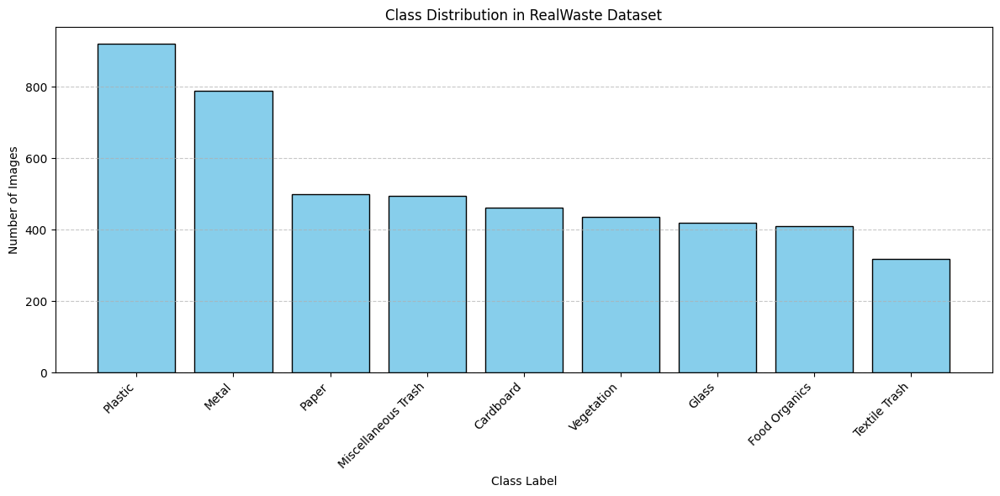

Plastic: 921 images
Metal: 790 images
Paper: 500 images
Miscellaneous Trash: 495 images
Cardboard: 461 images
Vegetation: 436 images
Glass: 420 images
Food Organics: 411 images
Textile Trash: 318 images


In [ ]:
import os
import matplotlib.pyplot as plt

# Count the number of files in each subdirectory of the dataset
class_counts = {}
for class_name in os.listdir(dataset_path):
    class_dir = os.path.join(dataset_path, class_name)
    if os.path.isdir(class_dir):
        # Count only files (images)
        num_images = len([f for f in os.listdir(class_dir) if os.path.isfile(os.path.join(class_dir, f))])
        class_counts[class_name] = num_images

# Sort classes by count for a cleaner visualization
sorted_classes = dict(sorted(class_counts.items(), key=lambda item: item[1], reverse=True))

# Plot the class distribution
plt.figure(figsize=(12, 6))
plt.bar(sorted_classes.keys(), sorted_classes.values(), color='skyblue', edgecolor='black')
plt.title('Class Distribution in RealWaste Dataset')
plt.xlabel('Class Label')
plt.ylabel('Number of Images')
plt.xticks(rotation=45, ha='right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# Display the numeric values
for cls, count in sorted_classes.items():
    print(f"{cls}: {count} images")

**Make image paths and labels, then split 70/15/15**

In [ ]:
# Class names = folder names. We sort them so the numbering is always the same
class_names = sorted(os.listdir(dataset_path))
num_classes = len(class_names)
print("Classes:", class_names)

# Make two lists: where each image is, and which class number it belongs to
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)
    for image_name in sorted(os.listdir(class_path)):
        image_paths.append(os.path.join(class_path, image_name))
        labels.append(class_number)

# Step 1: take 70% for training, keep 30% aside
# stratify=labels keeps the class proportions the same in every split
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths, labels, test_size=0.30, random_state=seed, stratify=labels)

# Step 2: divide the 30% equally -> 15% validation + 15% test
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths, temp_labels, test_size=0.50, random_state=seed, stratify=temp_labels)


print("Train:", len(train_paths), "| Val:", len(val_paths), "| Test:", len(test_paths))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Train: 3326 | Val: 713 | Test: 713


**Input pipeline**

In [ ]:

def load_image(image_path, label):
    image = tf.io.read_file(image_path)                       # read the file
    image = tf.image.decode_jpeg(image, channels=3)           # decode to RGB pixels
    image = tf.image.resize(image, [image_height, image_width])  # shrink to 64x64
    image = tf.cast(image, tf.float32) / 255.0                # scale pixels from 0-255 to 0-1
    return image, label
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
])

AUTOTUNE = tf.data.AUTOTUNE

# Training data: load -> cache in memory -> shuffle -> batch -> augment -> prefetch
train_ds = (tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
            .map(load_image, num_parallel_calls=AUTOTUNE)
            .cache()
            .shuffle(len(train_paths), seed=seed)
            .batch(batch_size)
            .map(lambda x, y: (data_augmentation(x, training=True), y),
                 num_parallel_calls=AUTOTUNE)
            .prefetch(AUTOTUNE))

# Validation data: no shuffle, no augmentation
val_ds = (tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
          .map(load_image, num_parallel_calls=AUTOTUNE)
          .batch(batch_size).cache().prefetch(AUTOTUNE))

# Test data: no shuffle (important! so predictions match the label order later)
test_ds = (tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
           .map(load_image, num_parallel_calls=AUTOTUNE)
           .batch(batch_size).cache().prefetch(AUTOTUNE))

# Quick check of one batch
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)   # expect (32, 64, 64, 3)

Image batch shape: (32, 64, 64, 3)


**Class weights**

In [ ]:
# Some classes have many more images than others (Plastic = 921, Textile = 318).
# Without weights, the model may just favour the big classes.
# "balanced" gives bigger weights to small classes, so their mistakes cost more.
weights = compute_class_weight(class_weight="balanced",
                               classes=np.arange(num_classes),
                               y=np.array(train_labels))

# Keras wants a dictionary like {0: weight, 1: weight, ...}
class_weights = {i: float(w) for i, w in enumerate(weights)}

for i, name in enumerate(class_names):
    print(f"{name:20s} weight = {class_weights[i]:.3f}")

Cardboard            weight = 1.144
Food Organics        weight = 1.283
Glass                weight = 1.257
Metal                weight = 0.668
Miscellaneous Trash  weight = 1.068
Paper                weight = 1.056
Plastic              weight = 0.573
Textile Trash        weight = 1.665
Vegetation           weight = 1.212


**Build Model B**

In [ ]:

def ds_block(x, filters, pool=True):
    x = layers.DepthwiseConv2D((3, 3), padding="same", use_bias=False)(x)  # step 1
    x = layers.BatchNormalization()(x)         # keeps values stable, trains faster
    x = layers.ReLU(max_value=6.0)(x)          # ReLU6 = min(max(0,x), 6), very cheap for hardware

    x = layers.Conv2D(filters, (1, 1), use_bias=False)(x)                  # step 2
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    if pool:
        x = layers.MaxPooling2D((2, 2))(x)     # halves the image size (e.g. 32x32 -> 16x16)
    return x


def build_model_b():
    inputs = keras.Input(shape=(image_height, image_width, 3))   # 64x64 RGB image

   # Use a normal convolution as the first feature extraction layer
    x = layers.Conv2D(16, (3, 3), padding="same", use_bias=False)(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)
    x = layers.MaxPooling2D((2, 2))(x)          # -> 32 x 32 x 16

    # Four depthwise separable blocks, channels grow: 32 -> 64 -> 128 -> 256
    x = ds_block(x, 32,  pool=True)             # -> 16 x 16 x 32
    x = ds_block(x, 64,  pool=True)             # -> 8 x 8 x 64
    x = ds_block(x, 128, pool=True)             # -> 4 x 4 x 128
    x = ds_block(x, 256, pool=False)            # -> 4 x 4 x 256 (no pooling at the end)

    # Global average pooling: each 4x4 map becomes 1 number -> 256 numbers.
    # This avoids a huge Flatten + Dense layer (saves a lot of parameters).
    x = layers.GlobalAveragePooling2D()(x)

    x = layers.Dropout(0.3)(x)                  # randomly switches off 30% neurons to reduce overfitting
    x = layers.Dense(64)(x)                     # fully connected layer with 64 units
    x = layers.ReLU(max_value=6.0)(x)

    # Output layer: 9 numbers (one per class), softmax makes them add up to 1 (probabilities)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    return keras.Model(inputs, outputs, name="model_b_dsconv")


model_b = build_model_b()
model_b.summary()

# Count only trainable parameters (assignment says must be under 100,000)
trainable = int(sum(np.prod(w.shape) for w in model_b.trainable_weights))
print("Trainable parameters:", trainable)

# This line stops the notebook with an error if we ever go over the limit
assert trainable < 100_000, "Model B must be under 100,000 trainable parameters!"
print("Parameter limit OK")

Model: "model_b_dsconv"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 64, 64, 16)     │           432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_27          │ (None, 64, 64, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_30 (ReLU)                 │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_12             │ (None, 32, 32, 16)     │           144 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_28          │ (None, 32, 32, 16)     │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_31 (ReLU)                 │ (None, 32, 32, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 32, 32, 32)     │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_29          │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_32 (ReLU)                 │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_13             │ (None, 16, 16, 32)     │           288 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_30          │ (None, 16, 16, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_33 (ReLU)                 │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 16, 16, 64)     │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_31          │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_34 (ReLU)                 │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ depthwise_conv2d_14             │ (None, 8, 8, 64)       │           576 │
│ (DepthwiseConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_32          │ (None, 8, 8, 64)       │           25

 Total params: 66,089 (258.16 KB)

 Trainable params: 64,617 (252.41 KB)

 Non-trainable params: 1,472 (5.75 KB)

Trainable parameters: 64617
Parameter limit OK


**Manual parameter calculation (for the report)**

In [ ]:
# We calculate the parameters by hand (with formulas) and compare with Keras.
# Same idea  used for Model A.

# Stem: normal 3x3 conv, 3 input channels, 16 filters (no bias) + BatchNorm
# BatchNorm has 2 trainable params per channel (gamma and beta)
stem_conv = 3 * 3 * 3 * 16
stem_bn   = 2 * 16

# One depthwise separable block, going from cin channels to cout channels
def block_params(cin, cout):
    dw    = 3 * 3 * cin      # depthwise 3x3: one 3x3 filter per input channel
    dw_bn = 2 * cin          # BatchNorm after depthwise
    pw    = cin * cout       # pointwise 1x1: cin x cout weights
    pw_bn = 2 * cout         # BatchNorm after pointwise
    return dw + dw_bn + pw + pw_bn

b1 = block_params(16, 32)
b2 = block_params(32, 64)
b3 = block_params(64, 128)
b4 = block_params(128, 256)

dense1 = 256 * 64 + 64                       # Dense(64): weights + biases
out    = 64 * num_classes + num_classes      # Output Dense(9): weights + biases

manual_total = stem_conv + stem_bn + b1 + b2 + b3 + b4 + dense1 + out

print("Stem (conv + BN):", stem_conv + stem_bn)
print("DS Block 1 (16->32):  ", b1)
print("DS Block 2 (32->64):  ", b2)
print("DS Block 3 (64->128): ", b3)
print("DS Block 4 (128->256):", b4)
print("Dense(64):", dense1)
print("Output layer:", out)
print("-----------------------------")
print("Manual trainable total:", manual_total)
print("Keras trainable total :", trainable)   # these two should be exactly equal

Stem (conv + BN): 464
DS Block 1 (16->32):   752
DS Block 2 (32->64):   2528
DS Block 3 (64->128):  9152
DS Block 4 (128->256): 34688
Dense(64): 16448
Output layer: 585
-----------------------------
Manual trainable total: 64617
Keras trainable total : 64617


**Compare MACs with Model A**

In [ ]:
# Model A rebuilt here ONLY to count its MACs (we don't train it in this notebook)
def build_model_a():
    inputs = keras.Input(shape=(image_height, image_width, 3))
    x = layers.Conv2D(16, (3,3), activation="relu", padding="same")(inputs)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Conv2D(32, (3,3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Conv2D(64, (3,3), activation="relu", padding="same")(x)
    x = layers.MaxPooling2D((2,2))(x)
    x = layers.Flatten()(x)
    x = layers.Dense(64, activation="relu")(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)
    return keras.Model(inputs, outputs, name="model_a")

# MAC = multiply-accumulate operations = a measure of computation cost.
# For a conv layer: output_height * output_width * kernel_h * kernel_w * in_channels * out_channels
def count_macs(model):
    total = 0
    for layer in model.layers:
        if isinstance(layer, layers.DepthwiseConv2D):       # depthwise: no "out_channels" multiplication
            kh, kw, cin, _ = layer.kernel.shape
            _, h, w, _ = layer.output.shape
            total += h * w * kh * kw * cin
        elif isinstance(layer, layers.Conv2D):              # normal conv and 1x1 pointwise conv
            kh, kw, cin, cout = layer.kernel.shape
            _, h, w, _ = layer.output.shape
            total += h * w * kh * kw * cin * cout
        elif isinstance(layer, layers.Dense):               # dense: inputs * outputs
            cin, cout = layer.kernel.shape
            total += cin * cout
    return total

model_a_ref = build_model_a()
macs_a = count_macs(model_a_ref)
macs_b = count_macs(model_b)

print(f"Model A: {model_a_ref.count_params():,} params | {macs_a/1e6:.2f} M MACs")
print(f"Model B: {model_b.count_params():,} params | {macs_b/1e6:.2f} M MACs")
print(f"MAC reduction (A / B): {macs_a/macs_b:.2f}x")

Model A: 286,377 params | 11.47 M MACs
Model B: 66,089 params | 4.16 M MACs
MAC reduction (A / B): 2.76x


**Compile and train**

In [ ]:
# Set total epochs to 30
epochs = 30

# Small helper that records how long each epoch takes (needed for the comparison table)
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None):
        self.times = []
    def on_epoch_begin(self, epoch, logs=None):
        self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None):
        self.times.append(time.time() - self.t0)

# Compile = tell the model HOW to learn
model_b.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),   # Adam with lr 0.001
    loss="sparse_categorical_crossentropy",                # labels are integers 0-8
    metrics=["accuracy"],
)

timer = EpochTimer()

callbacks = [
    timer,
    # Save the model only when validation accuracy improves
    keras.callbacks.ModelCheckpoint("model_b_best.keras", monitor="val_accuracy",
                                    save_best_only=True, verbose=1),
    # Reduce learning rate if validation loss plateaus for 4 epochs
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5,
                                      patience=4, min_lr=1e-5, verbose=1),
]

# Train the model for 30 epochs using class weights
history = model_b.fit(
    train_ds,
    validation_data=val_ds,
    epochs=epochs,                # Trains for exactly 30 epochs
    class_weight=class_weights,
    callbacks=callbacks,
)

print(f"Average training time per epoch: {np.mean(timer.times):.2f} seconds")

Epoch 1/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 187ms/step - accuracy: 0.2379 - loss: 1.9995
Epoch 1: val_accuracy improved from None to 0.08836, saving model to model_b_best.keras

Epoch 1: finished saving model to model_b_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 29s 217ms/step - accuracy: 0.3214 - loss: 1.7988 - val_accuracy: 0.0884 - val_loss: 2.2172 - learning_rate: 0.0010
Epoch 2/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step - accuracy: 0.4601 - loss: 1.4568
Epoch 2: val_accuracy improved from 0.08836 to 0.19355, saving model to model_b_best.keras

Epoch 2: finished saving model to model_b_best.keras
104/104 ━━━━━━━━━━━━━━━━━━━━ 41s 222ms/step - accuracy: 0.4633 - loss: 1.4342 - val_accuracy: 0.1935 - val_loss: 2.3035 - learning_rate: 0.0010
Epoch 3/30
104/104 ━━━━━━━━━━━━━━━━━━━━ 0s 189ms/step - accuracy: 0.4953 - loss: 1.2764
Epoch 3: val_accuracy did not improve from 0.19355
104/104 ━━━━━━━━━━━━━━━━━━━━ 21s 198ms/step - accuracy: 0.5075 - loss: 1.2801 - val_accuracy: 0.1332 - val_los

**Loss and accuracy curves**

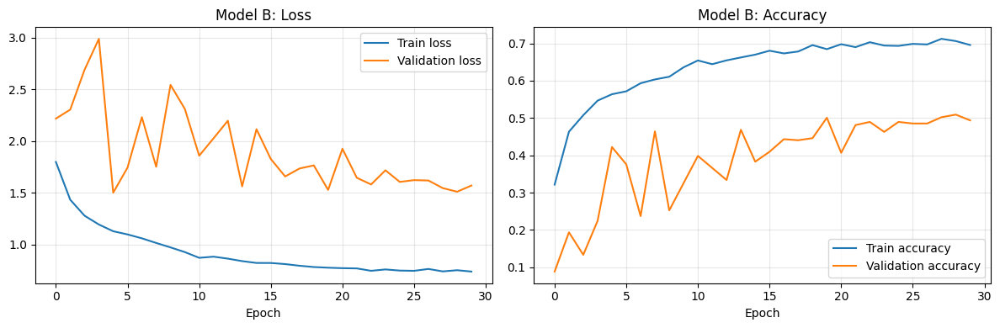

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# Left graph: loss (should go down)
ax[0].plot(history.history["loss"], label="Train loss")
ax[0].plot(history.history["val_loss"], label="Validation loss")
ax[0].set_title("Model B: Loss")
ax[0].set_xlabel("Epoch")
ax[0].legend()
ax[0].grid(alpha=0.3)

# Right graph: accuracy (should go up)
ax[1].plot(history.history["accuracy"], label="Train accuracy")
ax[1].plot(history.history["val_accuracy"], label="Validation accuracy")
ax[1].set_title("Model B: Accuracy")
ax[1].set_xlabel("Epoch")
ax[1].legend()
ax[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig("model_b_curves.png", dpi=150)   # saved image for the report
plt.show()

**Test evaluation, confusion matrix, precision and recall**

Test loss: 1.4690 | Test accuracy: 0.5203

Classification report:

                     precision    recall  f1-score   support

          Cardboard     0.4656    0.8841    0.6100        69
      Food Organics     0.5957    0.4516    0.5138        62
              Glass     0.7500    0.5238    0.6168        63
              Metal     0.6867    0.4831    0.5672       118
Miscellaneous Trash     0.3857    0.3600    0.3724        75
              Paper     0.3537    0.6933    0.4685        75
            Plastic     0.6761    0.3478    0.4593       138
      Textile Trash     0.4074    0.2292    0.2933        48
         Vegetation     0.5806    0.8308    0.6835        65

           accuracy                         0.5203       713
          macro avg     0.5446    0.5337    0.5094       713
       weighted avg     0.5658    0.5203    0.5115       713

Macro precision: 0.5446 | Macro recall: 0.5337


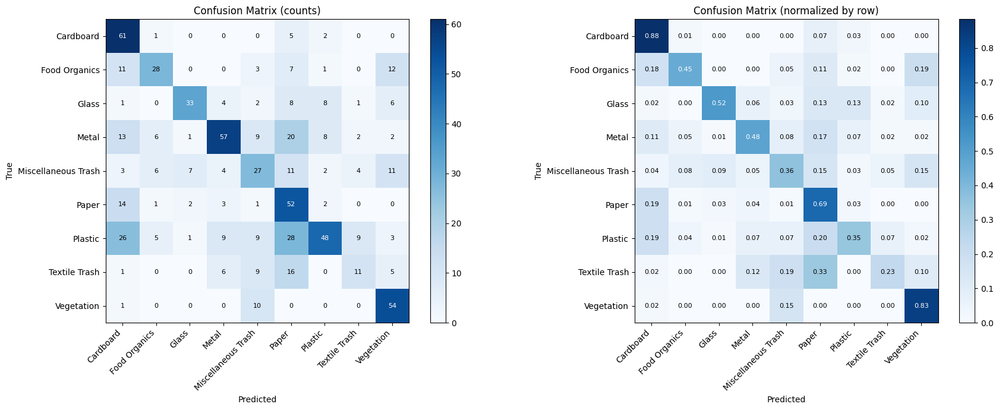

In [ ]:
# Load the best saved model (the epoch with highest validation accuracy)
best_model = keras.models.load_model("model_b_best.keras")

# Final score on the test set (images the model has never seen)
test_loss, test_acc = best_model.evaluate(test_ds, verbose=0)
print(f"Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}")

# Get predictions. Model gives 9 probabilities per image; argmax picks the biggest one
y_prob = best_model.predict(test_ds, verbose=0)
y_pred = np.argmax(y_prob, axis=1)
y_true = np.array(test_labels)    # real labels (same order because test_ds is not shuffled)

# Precision / recall / f1 for each class
print("\nClassification report:\n")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

# Overall (macro) precision and recall = simple average over the 9 classes
macro_p = precision_score(y_true, y_pred, average="macro")
macro_r = recall_score(y_true, y_pred, average="macro")
print(f"Macro precision: {macro_p:.4f} | Macro recall: {macro_r:.4f}")

# ---- Confusion matrix ----
# Rows = true class, columns = predicted class. Diagonal = correct predictions.
cm = confusion_matrix(y_true, y_pred)
cm_norm = cm.astype("float") / cm.sum(axis=1, keepdims=True)   # each row as a percentage

fig, ax = plt.subplots(1, 2, figsize=(18, 7))
for a, data, title, fmt in [(ax[0], cm, "Confusion Matrix (counts)", "d"),
                            (ax[1], cm_norm, "Confusion Matrix (normalized by row)", ".2f")]:
    im = a.imshow(data, cmap="Blues")
    a.set_title(title)
    a.set_xticks(range(num_classes))
    a.set_yticks(range(num_classes))
    a.set_xticklabels(class_names, rotation=45, ha="right")
    a.set_yticklabels(class_names)
    a.set_xlabel("Predicted")
    a.set_ylabel("True")

    # write the number inside each box (white text on dark boxes so it's readable)
    thresh = data.max() / 2
    for i in range(num_classes):
        for j in range(num_classes):
            a.text(j, i, format(data[i, j], fmt), ha="center", va="center",
                   color="white" if data[i, j] > thresh else "black", fontsize=8)
    plt.colorbar(im, ax=a, fraction=0.046)

plt.tight_layout()
plt.savefig("model_b_confusion_matrix.png", dpi=150)
plt.show()

**Model size and TFLite**

In [ ]:
# Size of the saved model file on disk
size_keras_kb = os.path.getsize("model_b_best.keras") / 1024

# Theoretical size: each parameter is a 32-bit float = 4 bytes
size_fp32_kb_est = best_model.count_params() * 4 / 1024

print(f"Keras file size       : {size_keras_kb:.1f} KB")
print(f"Estimated float32 size: {size_fp32_kb_est:.1f} KB")

# Convert to TFLite = the format used on Raspberry Pi / microcontrollers.
# Wrapped in try/except so the notebook doesn't crash if conversion has a problem.
try:
    # normal float32 version
    conv = tf.lite.TFLiteConverter.from_keras_model(best_model)
    tflite_fp32 = conv.convert()
    open("model_b_fp32.tflite", "wb").write(tflite_fp32)

    # quantized version (weights stored as 8-bit -> about 4x smaller)
    conv = tf.lite.TFLiteConverter.from_keras_model(best_model)
    conv.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_q = conv.convert()
    open("model_b_int8.tflite", "wb").write(tflite_q)

    print(f"TFLite float32  : {len(tflite_fp32)/1024:.1f} KB")
    print(f"TFLite quantized: {len(tflite_q)/1024:.1f} KB")
except Exception as e:
    print("TFLite conversion skipped:", e)

Keras file size       : 915.0 KB
Estimated float32 size: 258.2 KB
Saved artifact at '/tmp/tmpiujcbwjq'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name='input_layer_6')
Output Type:
  TensorSpec(shape=(None, 9), dtype=tf.float32, name=None)
Captures:
  138280324127568: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324131792: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324131600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324131984: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324127376: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324132176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324136400: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324136208: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280350992528: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138280324127760: Te


---
## Part 4 - Optimizer Selection, Training and Evaluation


<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/lochana-training/Lochana_Training_Evaluation.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03- NEXORA

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [ ]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [ ]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation


In [ ]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

In [ ]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [            <=>     ] 656.65M  3.47MB/s    in 5m 6s   


In [ ]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

In [ ]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [ ]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Glass', 'Cardboard', 'Metal', 'Food Organics', 'Textile Trash', 'Plastic', 'Paper', 'Miscellaneous Trash', 'Vegetation']


In [ ]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [ ]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

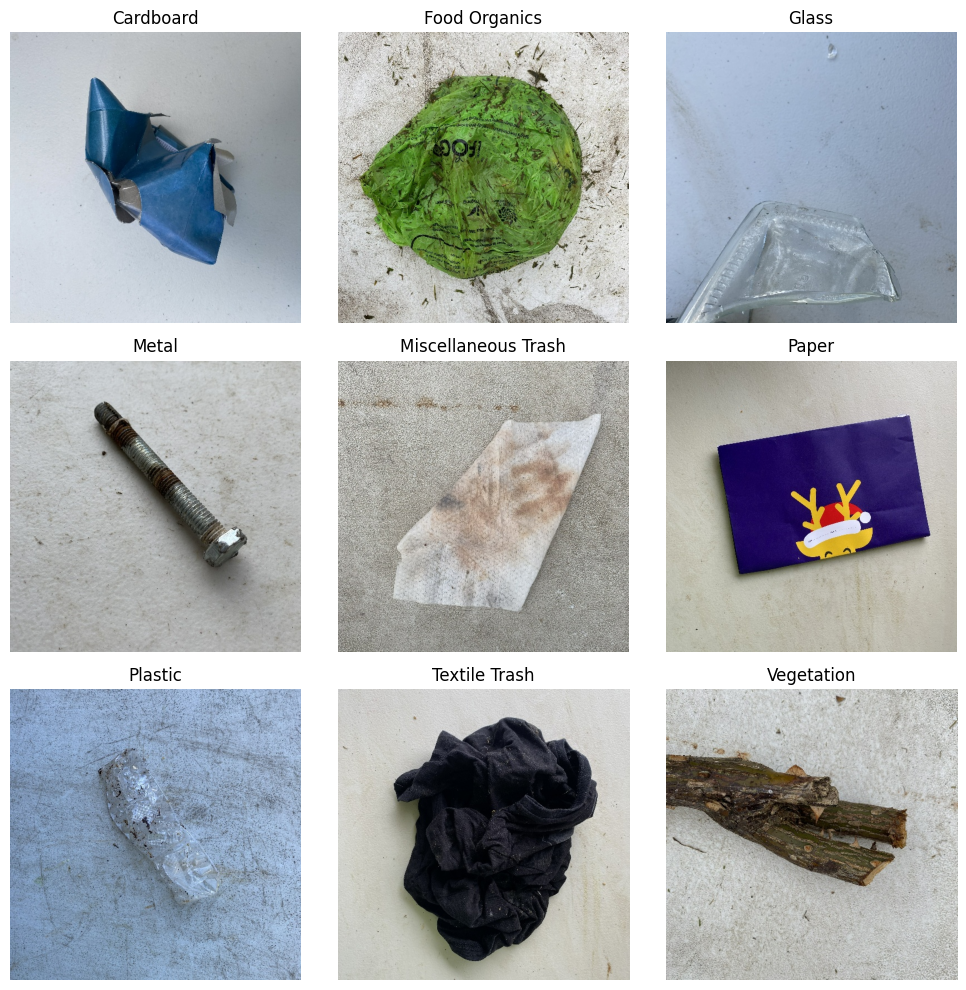

In [ ]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels

In [ ]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

In [ ]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [ ]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [ ]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [ ]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing

In [ ]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [ ]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


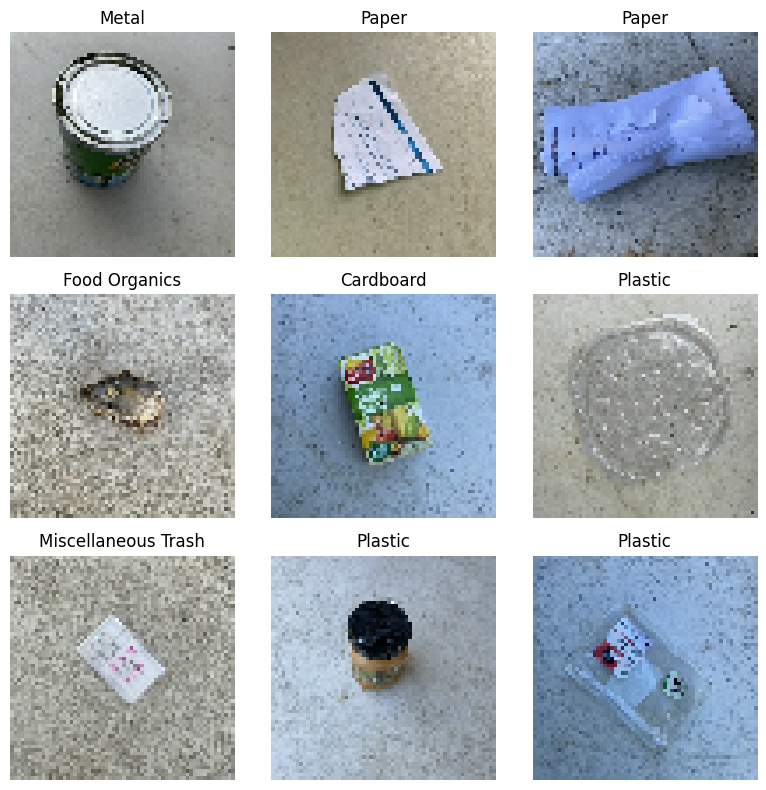

In [ ]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Optimizer Selection and Training

In [ ]:

# Optimizers that will be compared
learning_rate = 0.001

def make_optimizer(name):
    if name == "sgd":
        return keras.optimizers.SGD(
            learning_rate=learning_rate
        )

    if name == "momentum":
        return keras.optimizers.SGD(
            learning_rate=learning_rate,
            momentum=0.9
        )

    if name == "adam":
        return keras.optimizers.Adam(
            learning_rate=learning_rate
        )

    raise ValueError(f"Unknown optimizer: {name}")

print("SGD optimizer prepared")
print("SGD with Momentum optimizer prepared")
print("Adam selected as the main optimizer")

SGD optimizer prepared
SGD with Momentum optimizer prepared
Adam selected as the main optimizer


In [ ]:
def train_model(model, optimizer, epochs=20):

    model.compile(
        optimizer=optimizer,
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    start_time = time.time()

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=epochs,
        verbose=1
    )

    end_time = time.time()

    training_time = end_time - start_time

    return history, training_time

Add Exact model A architecture

In [ ]:

def build_model_a():
    model = keras.Sequential([
        layers.Input(shape=(64, 64, 3)),

        layers.Conv2D(
            16, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            32, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(
            64, (3, 3),
            activation="relu",
            padding="same"
        ),
        layers.MaxPooling2D((2, 2)),

        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ])

    return model




In [ ]:
num_classes = len(class_names)
print("Number of classes:", num_classes)

Number of classes: 9


In [ ]:
temp_a = build_model_a()
print("Model A parameters:", temp_a.count_params())

Model A parameters: 286377


Add exact Model B architecture


In [ ]:

def ds_block(x, filters, pool=True):
    x = layers.DepthwiseConv2D(
        (3, 3),
        padding="same",
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    x = layers.Conv2D(
        filters,
        (1, 1),
        use_bias=False
    )(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)

    if pool:
        x = layers.MaxPooling2D((2, 2))(x)

    return x


def build_model_b():
    inputs = keras.Input(shape=(64, 64, 3))

    x = layers.Conv2D(
        16, (3, 3),
        padding="same",
        use_bias=False
    )(inputs)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU(max_value=6.0)(x)
    x = layers.MaxPooling2D((2, 2))(x)

    x = ds_block(x, 32, pool=True)
    x = ds_block(x, 64, pool=True)
    x = ds_block(x, 128, pool=True)
    x = ds_block(x, 256, pool=False)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    x = layers.Dense(64)(x)
    x = layers.ReLU(max_value=6.0)(x)

    outputs = layers.Dense(
        num_classes,
        activation="softmax"
    )(x)

    return keras.Model(inputs, outputs)


In [ ]:
temp_b = build_model_b()

trainable_b = sum(
    np.prod(w.shape)
    for w in temp_b.trainable_weights
)

print("Model B trainable parameters:", trainable_b)

Model B trainable parameters: 64617


##Loss curve code


In [ ]:
def plot_loss_curves(history, title):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["loss"],
        label="Training Loss"
    )

    plt.plot(
        history.history["val_loss"],
        label="Validation Loss"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

In [ ]:
def plot_accuracy_curves(history, title):

    plt.figure(figsize=(8, 5))

    plt.plot(
        history.history["accuracy"],
        label="Training Accuracy"
    )

    plt.plot(
        history.history["val_accuracy"],
        label="Validation Accuracy"
    )

    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.title(title)
    plt.legend()
    plt.grid(True)
    plt.show()

##Evaluation code

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)



def evaluate_model(model):
    test_loss, _ = model.evaluate(
        test_ds,
        verbose=0
    )

    y_true = []
    y_pred = []

    for images, labels in test_ds:
        predictions = model.predict(
            images,
            verbose=0
        )

        predicted_labels = np.argmax(
            predictions,
            axis=1
        )

        y_true.extend(labels.numpy())
        y_pred.extend(predicted_labels)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    accuracy = accuracy_score(
        y_true, y_pred
    )

    precision = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    recall = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    f1 = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    return (
        y_true, y_pred, test_loss,
        accuracy, precision, recall, f1
    )


##Confusion Matrix

In [ ]:
import seaborn as sns

def plot_confusion_matrix(y_true, y_pred, title):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(10, 8))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.title(title)
    plt.xticks(rotation=45, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

##Results

In [ ]:
def print_results(
    accuracy,
    precision,
    recall,
    training_time
):

    print("Test Accuracy :", f"{accuracy:.4f}")
    print("Precision     :", f"{precision:.4f}")
    print("Recall        :", f"{recall:.4f}")
    print("Training Time :", f"{training_time:.2f} seconds")


In [ ]:

num_classes = len(class_names)

print("Number of classes:", num_classes)


Number of classes: 9


In [ ]:
print("Training dataset:", train_ds)
print("Validation dataset:", val_ds)
print("Test dataset:", test_ds)
print("Classes:", class_names)
print("Number of classes:", num_classes)

Training dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Validation dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Test dataset: <_BatchDataset element_spec=(TensorSpec(shape=(None, 64, 64, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>
Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


## Model A Optimizer Experiment


In [ ]:
import time
optimizer_names = ["sgd", "momentum", "adam"]
optimizer_results = {}

for name in optimizer_names:
    print("\nTraining with:", name)

    # Reset random seeds
    random.seed(42)
    np.random.seed(42)
    tf.random.set_seed(42)

    # Build a fresh Model A
    model = build_model_a()

    history, training_time = train_model(
        model,
        make_optimizer(name),
        epochs=20
    )

    best_val_accuracy = max(
        history.history["val_accuracy"]
    )

    best_val_loss = min(
        history.history["val_loss"]
    )

    optimizer_results[name] = {
        "history": history,
        "training_time": training_time,
        "best_val_accuracy": best_val_accuracy,
        "best_val_loss": best_val_loss
    }



Training with: sgd
Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 154ms/step - accuracy: 0.1822 - loss: 2.1829 - val_accuracy: 0.1992 - val_loss: 2.1746
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 42s 182ms/step - accuracy: 0.1945 - loss: 2.1671 - val_accuracy: 0.1935 - val_loss: 2.1610
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 23s 154ms/step - accuracy: 0.1939 - loss: 2.1552 - val_accuracy: 0.1935 - val_loss: 2.1513
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 162ms/step - accuracy: 0.1939 - loss: 2.1471 - val_accuracy: 0.1935 - val_loss: 2.1453
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 154ms/step - accuracy: 0.1939 - loss: 2.1420 - val_accuracy: 0.1935 - val_loss: 2.1416
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 28s 154ms/step - accuracy: 0.1939 - loss: 2.1387 - val_accuracy: 0.1935 - val_loss: 2.1388
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 38s 151ms/step - accuracy: 0.1939 - loss: 2.1359 - val_accuracy: 0.1935 - val_loss: 2.1364
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 43s 172ms/step - accura

the comparison and select an optimizer


In [ ]:

for name, result in optimizer_results.items():
    print("\n", name)

    print(
        "Best validation accuracy:",
        round(result["best_val_accuracy"], 4)
    )

    print(
        "Best validation loss:",
        round(result["best_val_loss"], 4)
    )

    print(
        "Training time:",
        round(result["training_time"], 2),
        "seconds"
    )

selected_optimizer = max(
    optimizer_results,
    key=lambda name:
        optimizer_results[name]["best_val_accuracy"]
)

print("Selected optimizer:", selected_optimizer)



 sgd
Best validation accuracy: 0.1992
Best validation loss: 2.0981
Training time: 586.17 seconds

 momentum
Best validation accuracy: 0.547
Best validation loss: 1.2932
Training time: 627.28 seconds

 adam
Best validation accuracy: 0.6957
Best validation loss: 0.9951
Training time: 634.54 seconds
Selected optimizer: adam


##Train final model A

In [ ]:

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

final_model_a = build_model_a()

history_a, training_time_a = train_model(
    final_model_a,
    make_optimizer(selected_optimizer),
    epochs=20
)


Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 160ms/step - accuracy: 0.3103 - loss: 1.9003 - val_accuracy: 0.4418 - val_loss: 1.6394
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 157ms/step - accuracy: 0.4492 - loss: 1.4885 - val_accuracy: 0.5077 - val_loss: 1.4000
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 160ms/step - accuracy: 0.5225 - loss: 1.3215 - val_accuracy: 0.5273 - val_loss: 1.3310
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 157ms/step - accuracy: 0.5908 - loss: 1.1502 - val_accuracy: 0.5596 - val_loss: 1.2327
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 153ms/step - accuracy: 0.6263 - loss: 1.0396 - val_accuracy: 0.6115 - val_loss: 1.1487
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 171ms/step - accuracy: 0.6597 - loss: 0.9375 - val_accuracy: 0.6452 - val_loss: 1.0702
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 25s 156ms/step - accuracy: 0.6879 - loss: 0.8738 - val_accuracy: 0.6494 - val_loss: 1.0117
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 152ms/step - accuracy: 0.7210 - loss: 0

##Train final model B

In [ ]:

random.seed(42)
np.random.seed(42)
tf.random.set_seed(42)

final_model_b = build_model_b()

history_b, training_time_b = train_model(
    final_model_b,
    make_optimizer(selected_optimizer),
    epochs=20
)


Epoch 1/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 43s 243ms/step - accuracy: 0.3821 - loss: 1.7170 - val_accuracy: 0.1935 - val_loss: 2.2243
Epoch 2/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 41s 242ms/step - accuracy: 0.5301 - loss: 1.3102 - val_accuracy: 0.0884 - val_loss: 2.4961
Epoch 3/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 38s 227ms/step - accuracy: 0.5953 - loss: 1.1199 - val_accuracy: 0.1711 - val_loss: 3.1519
Epoch 4/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 218ms/step - accuracy: 0.6524 - loss: 0.9759 - val_accuracy: 0.2370 - val_loss: 2.6364
Epoch 5/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 30s 206ms/step - accuracy: 0.6687 - loss: 0.8847 - val_accuracy: 0.3871 - val_loss: 2.0713
Epoch 6/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 239ms/step - accuracy: 0.7138 - loss: 0.8108 - val_accuracy: 0.6199 - val_loss: 1.0745
Epoch 7/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 30s 215ms/step - accuracy: 0.7336 - loss: 0.7297 - val_accuracy: 0.4123 - val_loss: 1.9518
Epoch 8/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 30s 205ms/step - accuracy: 0.7637 - loss: 0

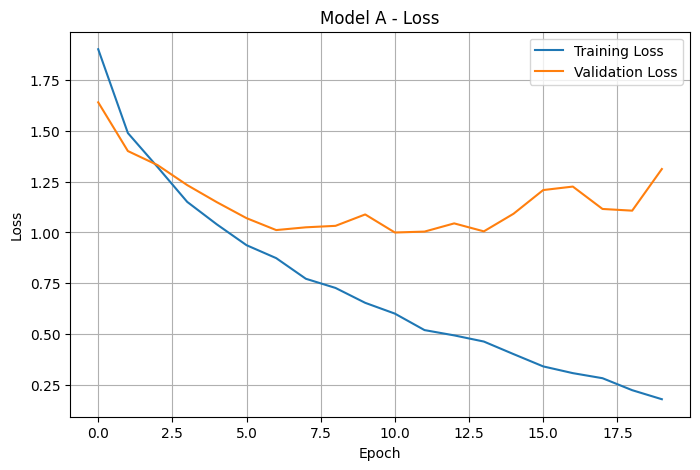

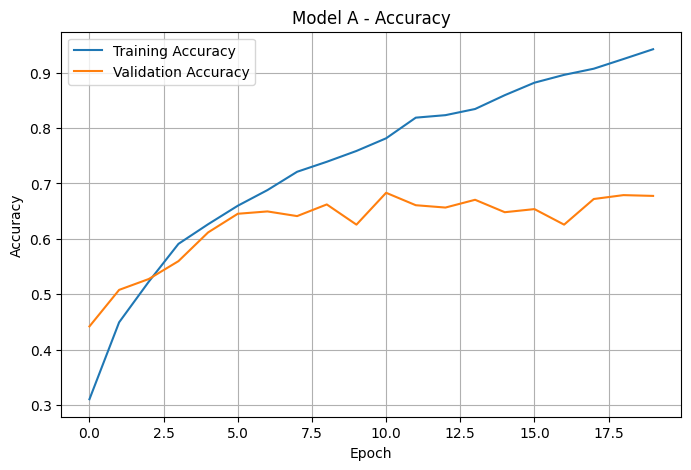

In [ ]:
plot_loss_curves(history_a, "Model A - Loss")
plot_accuracy_curves(history_a, "Model A - Accuracy")

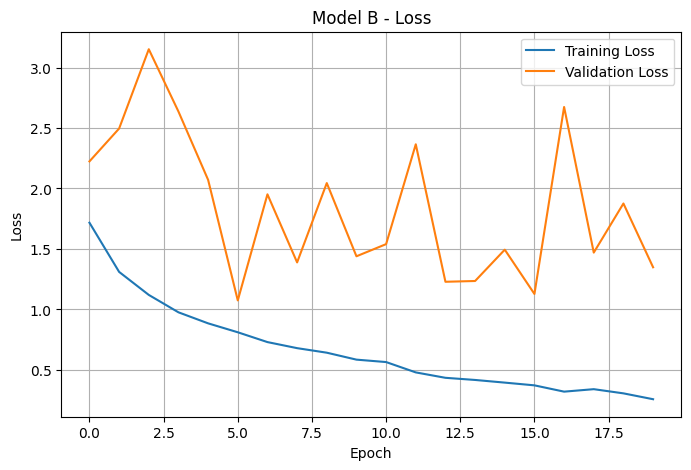

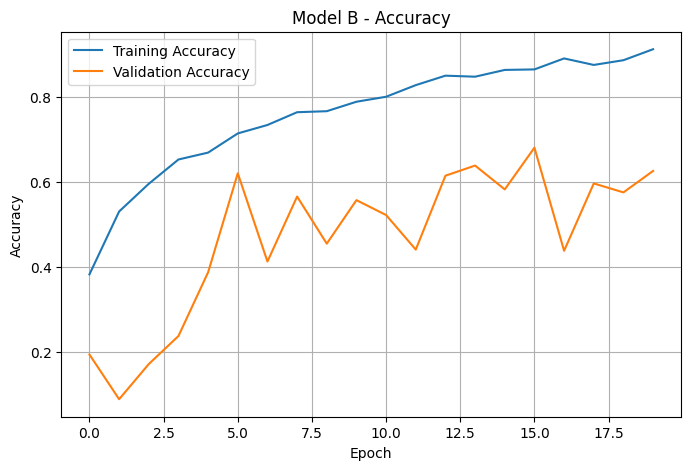

In [ ]:
plot_loss_curves(history_b, "Model B - Loss")
plot_accuracy_curves(history_b, "Model B - Accuracy")

##Evaluate model A

In [ ]:

(
    y_true_a,
    y_pred_a,
    test_loss_a,
    accuracy_a,
    precision_a,
    recall_a,
    f1_a
) = evaluate_model(final_model_a)

print("Model A")
print("Test loss:", round(test_loss_a, 4))
print("Test accuracy:", round(accuracy_a, 4))
print("Precision:", round(precision_a, 4))
print("Recall:", round(recall_a, 4))
print("F1-score:", round(f1_a, 4))
print(
    "Training time:",
    round(training_time_a, 2),
    "seconds"
)

print(
    classification_report(
        y_true_a,
        y_pred_a,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


Model A
Test loss: 1.4122
Test accuracy: 0.6452
Precision: 0.6527
Recall: 0.6452
F1-score: 0.6422
Training time: 561.37 seconds
                     precision    recall  f1-score   support

          Cardboard     0.6667    0.6667    0.6667        69
      Food Organics     0.7826    0.5806    0.6667        62
              Glass     0.8409    0.5873    0.6916        63
              Metal     0.6387    0.6441    0.6414       118
Miscellaneous Trash     0.3438    0.2933    0.3165        75
              Paper     0.6914    0.7467    0.7179        75
            Plastic     0.5815    0.7754    0.6646       138
      Textile Trash     0.6923    0.5625    0.6207        48
         Vegetation     0.7910    0.8154    0.8030        65

           accuracy                         0.6452       713
          macro avg     0.6699    0.6302    0.6432       713
       weighted avg     0.6527    0.6452    0.6422       713



##Evaluate model B

In [ ]:

(
    y_true_b,
    y_pred_b,
    test_loss_b,
    accuracy_b,
    precision_b,
    recall_b,
    f1_b
) = evaluate_model(final_model_b)

print("Model B")
print("Test loss:", round(test_loss_b, 4))
print("Test accuracy:", round(accuracy_b, 4))
print("Precision:", round(precision_b, 4))
print("Recall:", round(recall_b, 4))
print("F1-score:", round(f1_b, 4))
print(
    "Training time:",
    round(training_time_b, 2),
    "seconds"
)

print(
    classification_report(
        y_true_b,
        y_pred_b,
        labels=list(range(num_classes)),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)


Model B
Test loss: 1.4195
Test accuracy: 0.6045
Precision: 0.6317
Recall: 0.6045
F1-score: 0.5936
Training time: 708.88 seconds
                     precision    recall  f1-score   support

          Cardboard     0.6724    0.5652    0.6142        69
      Food Organics     0.8000    0.4516    0.5773        62
              Glass     0.6897    0.6349    0.6612        63
              Metal     0.5318    0.7797    0.6323       118
Miscellaneous Trash     0.4559    0.4133    0.4336        75
              Paper     0.8750    0.4667    0.6087        75
            Plastic     0.5345    0.6739    0.5962       138
      Textile Trash     0.6111    0.2292    0.3333        48
         Vegetation     0.6966    0.9538    0.8052        65

           accuracy                         0.6045       713
          macro avg     0.6519    0.5743    0.5847       713
       weighted avg     0.6317    0.6045    0.5936       713



Plotting the confusion matrices

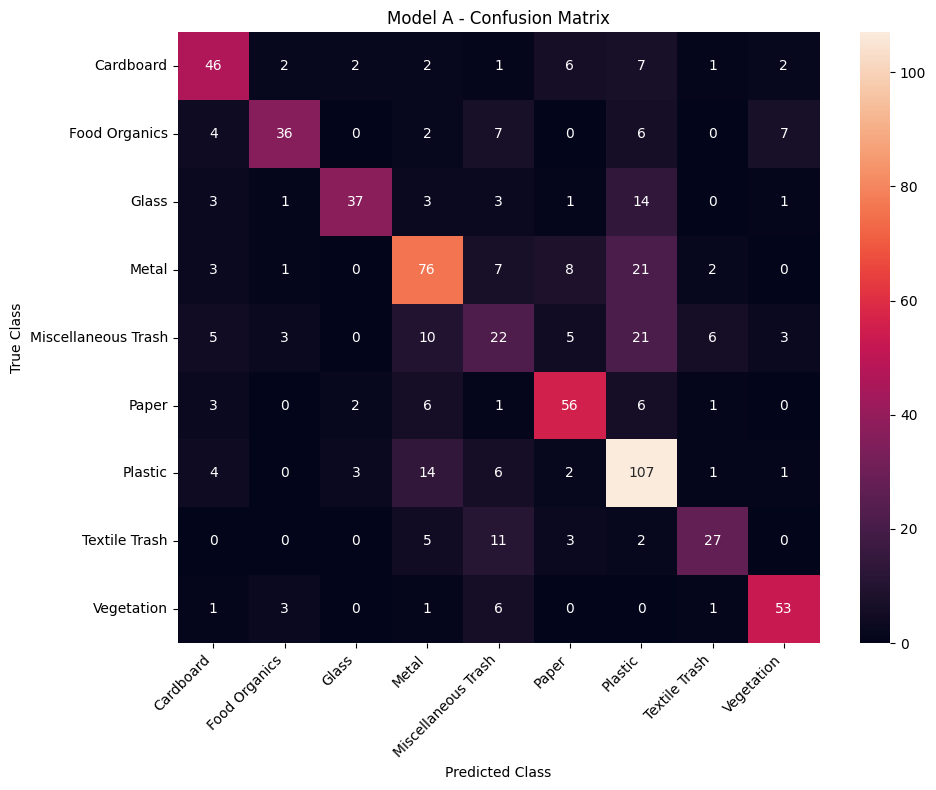

In [ ]:
plot_confusion_matrix(
    y_true_a,
    y_pred_a,
    "Model A - Confusion Matrix"
)

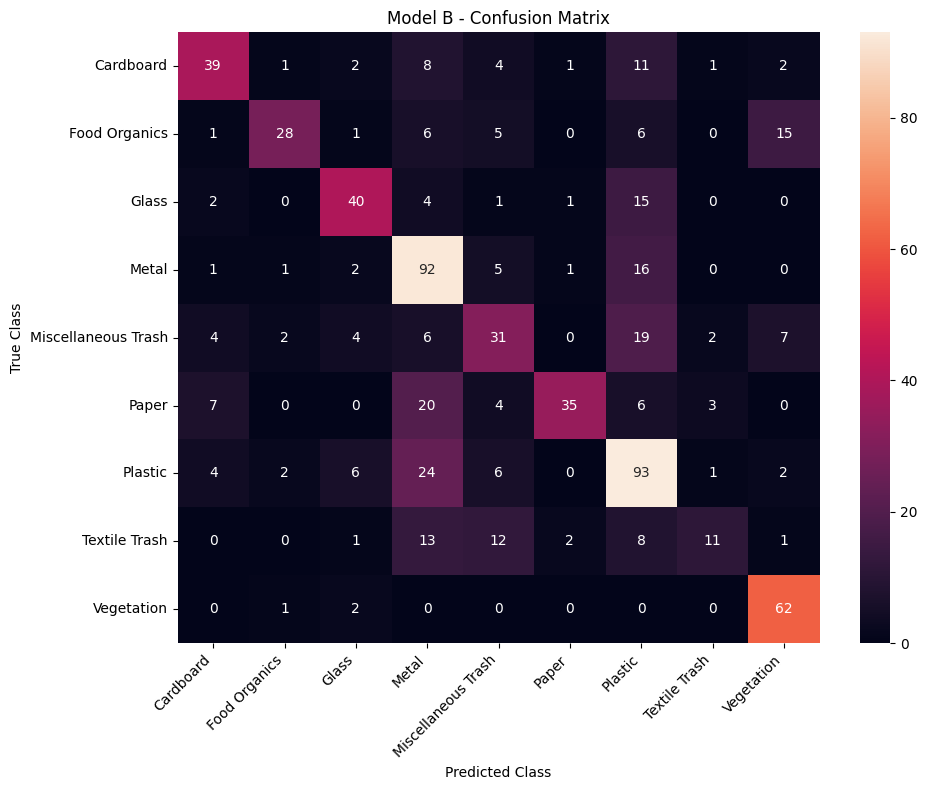

In [ ]:
plot_confusion_matrix(
    y_true_b,
    y_pred_b,
    "Model B - Confusion Matrix"
)

##Final comparison table

In [ ]:

import pandas as pd

comparison = pd.DataFrame({
    "Metric": [
        "Test Loss",
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Trainable Parameters",
        "Training Time (s)"
    ],
    "Model A": [
        test_loss_a,
        accuracy_a,
        precision_a,
        recall_a,
        f1_a,
        286377,
        training_time_a
    ],
    "Model B": [
        test_loss_b,
        accuracy_b,
        precision_b,
        recall_b,
        f1_b,
        64617,
        training_time_b
    ]
})

comparison


,Metric,Model A,Model B
0,Test Loss,1.412239,1.419549
1,Test Accuracy,0.645161,0.604488
2,Precision,0.652724,0.631676
3,Recall,0.645161,0.604488
4,F1-score,0.642180,0.593566
5,Trainable Parameters,286377.000000,64617.000000
6,Training Time (s),561.372622,708.882573



---
## Part 5 - Pretrained Models and Final Comparison


<a href="https://colab.research.google.com/github/ChamiruGajasinghe/NEXORA_CNN/blob/main/Data_preparation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EN3150 Assignment 03 - NEXORA

## Image classification with lightweight pretrained CNNs




In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print(tf.__version__)

2.21.0


In [ ]:
# image sizes
image_height = 64
image_width = 64

#this will use later during training
batch_size = 32
epochs = 20

print("Image size:", image_height, "x", image_width)

Image size: 64 x 64


In [ ]:
import random

seed = 42
random.seed(seed)
np.random.seed(seed)
tf.random.set_seed(seed)

print("Seed set to", seed)

Seed set to 42


## Data Preparation

Downloads the dataset, checks its classes, creates fair data splits, and converts image files into TensorFlow batches.



In [ ]:
import os
from sklearn.model_selection import train_test_split

### Loading the RealWaste dataset

The RealWaste dataset contains labelled photographs of waste items. Each folder represents one class, so the folder name is used as the ground-truth label.



In [ ]:
# downloading the RealWaste dataset from UCI
!wget -q --show-progress https://archive.ics.uci.edu/static/public/908/realwaste.zip -O realwaste.zip

realwaste.zip           [         <=>        ] 311.96M  29.3MB/s               ^C


In [ ]:
# extracting the dataset
!unzip -oq realwaste.zip -d realwaste_data

[realwaste.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of realwaste.zip or
        realwaste.zip.zip, and cannot find realwaste.zip.ZIP, period.


In [ ]:
# extracted files
print(os.listdir("realwaste_data"))

['realwaste-main']


In [ ]:
dataset_path = "realwaste_data/realwaste-main/RealWaste"

print(os.listdir(dataset_path))

['Miscellaneous Trash', 'Textile Trash', 'Cardboard', 'Plastic', 'Paper', 'Glass', 'Food Organics', 'Vegetation', 'Metal']


In [ ]:
# get class names
class_names = os.listdir(dataset_path)
class_names.sort()

print("Classes:", class_names)
print("Number of classes:", len(class_names))

Classes: ['Cardboard', 'Food Organics', 'Glass', 'Metal', 'Miscellaneous Trash', 'Paper', 'Plastic', 'Textile Trash', 'Vegetation']
Number of classes: 9


In [ ]:
# count images in each class
total_images = 0

for class_name in class_names:
    class_path = os.path.join(dataset_path, class_name)
    image_count = len(os.listdir(class_path))

    print(class_name, ":", image_count)
    total_images = total_images + image_count

print("Total images:", total_images)

Cardboard : 461
Food Organics : 411
Glass : 420
Metal : 790
Miscellaneous Trash : 495
Paper : 500
Plastic : 921
Textile Trash : 318
Vegetation : 436
Total images: 4752


### Sample images

A sample image from each class is displayed to Just get and idea and simple validation


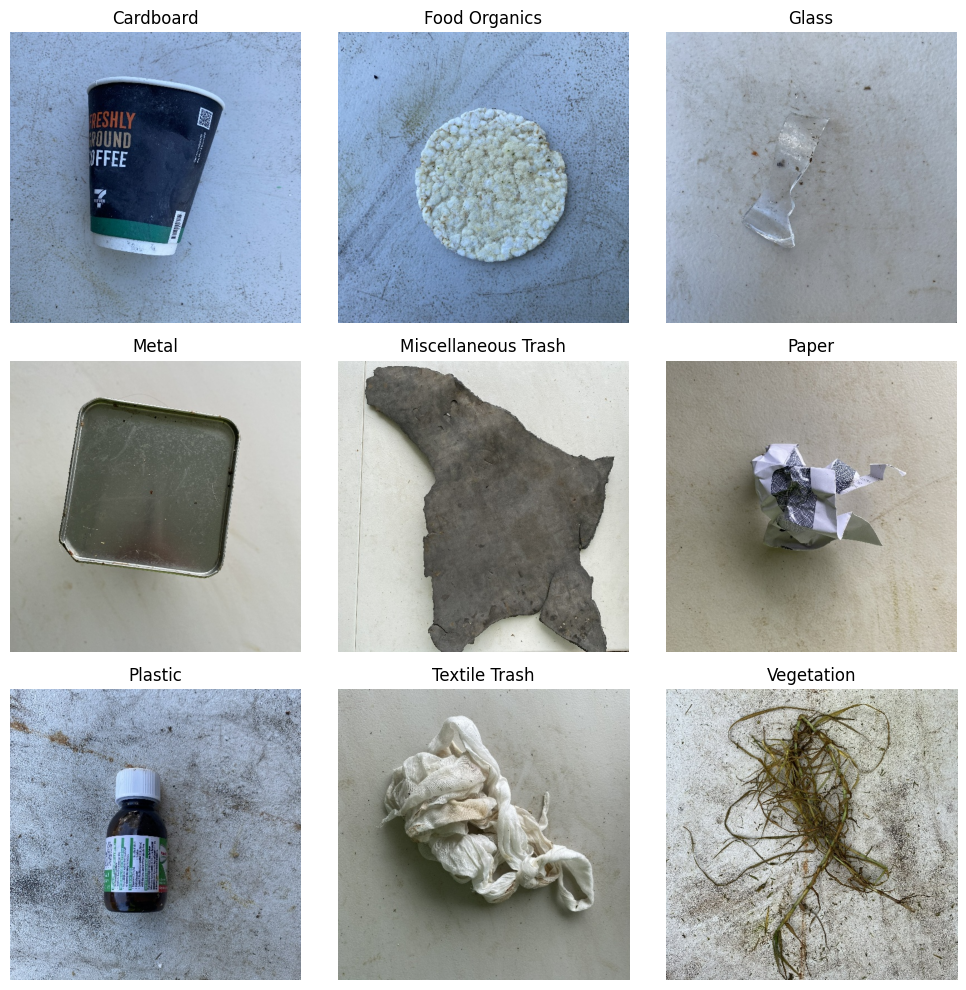

In [ ]:
# show one image from each class
plt.figure(figsize=(10, 10))

for i in range(len(class_names)):
    class_name = class_names[i]
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_name = image_files[0]

    image_path = os.path.join(class_path, image_name)
    image = plt.imread(image_path)

    plt.subplot(3, 3, i + 1)
    plt.imshow(image)
    plt.title(class_name)
    plt.axis("off")

plt.tight_layout()
plt.show()

### Image paths and labels




In [ ]:
image_paths = []
labels = []

for class_number, class_name in enumerate(class_names):
    class_path = os.path.join(dataset_path, class_name)

    image_files = os.listdir(class_path)
    image_files.sort()

    for image_name in image_files:
        image_path = os.path.join(class_path, image_name)

        image_paths.append(image_path)
        labels.append(class_number)

print("Images:", len(image_paths))
print("Labels:", len(labels))

Images: 4752
Labels: 4752


### Train, validation and test split

The images are divided into three independent groups:

- **Training set (70%)**
- **Validation set (15%)**
- **Test set (15%)**

The fixed random seed makes the split reproducible, so future runs use the same examples and can be compared fairly.


In [ ]:
# keep 70% for training
train_paths, temp_paths, train_labels, temp_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.30,
    random_state=seed,
    stratify=labels
)

In [ ]:
# divide the remaining 30% equally
val_paths, test_paths, val_labels, test_labels = train_test_split(
    temp_paths,
    temp_labels,
    test_size=0.50,
    random_state=seed,
    stratify=temp_labels
)

In [ ]:
print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Testing images:", len(test_paths))

Training images: 3326
Validation images: 713
Testing images: 713


In [ ]:
print("Training:", round(len(train_paths) / total_images * 100, 2), "%")
print("Validation:", round(len(val_paths) / total_images * 100, 2), "%")
print("Testing:", round(len(test_paths) / total_images * 100, 2), "%")

Training: 69.99 %
Validation: 15.0 %
Testing: 15.0 %


### Image preprocessing




In [ ]:
def load_image(image_path, label):

    image = tf.io.read_file(image_path)
    image = tf.image.decode_jpeg(image, channels=3)

    image = tf.image.resize(
        image,
        [image_height, image_width]
    )

    image = tf.cast(image, tf.float32)
    image = image / 255.0

    return image, label

In [ ]:
train_ds = tf.data.Dataset.from_tensor_slices(
    (train_paths, train_labels)
)

train_ds = train_ds.map(load_image)

train_ds = train_ds.shuffle(
    len(train_paths),
    seed=seed
)

train_ds = train_ds.batch(batch_size)

In [ ]:
val_ds = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

val_ds = val_ds.map(load_image)
val_ds = val_ds.batch(batch_size)

In [ ]:
test_ds = tf.data.Dataset.from_tensor_slices(
    (test_paths, test_labels)
)

test_ds = test_ds.map(load_image)
test_ds = test_ds.batch(batch_size)

In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 64, 64, 3)
Label batch shape: (32,)


In [ ]:
for images, batch_labels in train_ds.take(1):
    print("Minimum value:", tf.reduce_min(images).numpy())
    print("Maximum value:", tf.reduce_max(images).numpy())

Minimum value: 0.0
Maximum value: 1.0


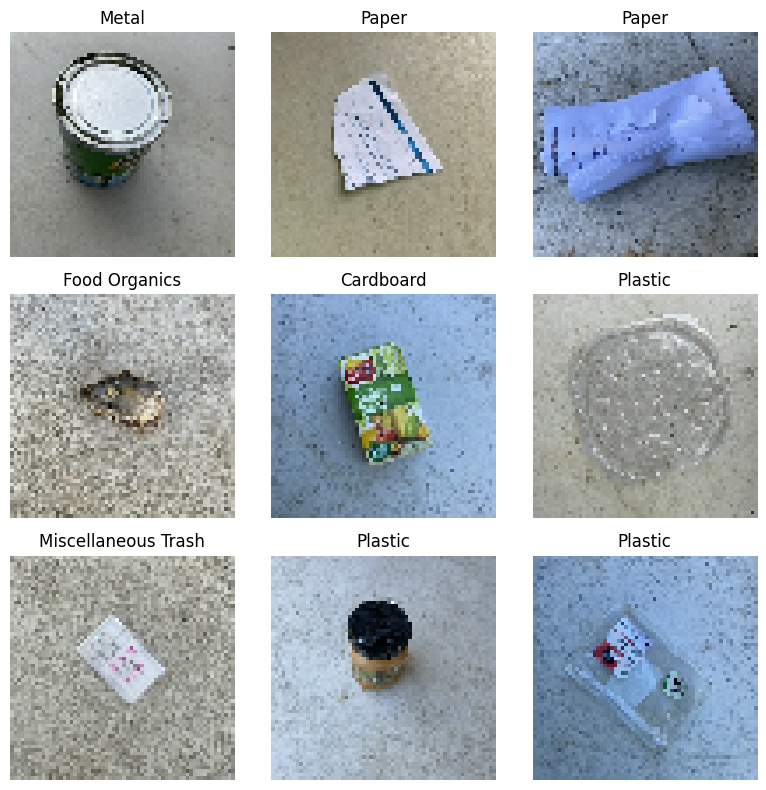

In [ ]:
for images, batch_labels in train_ds.take(1):

    plt.figure(figsize=(8, 8))

    for i in range(9):
        plt.subplot(3, 3, i + 1)
        plt.imshow(images[i])
        plt.title(class_names[batch_labels[i]])
        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Lightweight Pretrained Models


The two-stage strategy used here:

1. **Feature extraction**: freeze the pretrained base and learn only the new classifier.
2. **Fine-tuning**: unfreeze only the final base layers and continue with a much smaller learning rate.

This is used when the target data set is compared not very large and so to reduce the risk of destroying useful pretrained features.


## 1. MobileNetV2

This uses inverted residual blocks and depthwise separable convolutions to reduce computation while retaining useful image features.

The base is loaded with ImageNet weights. Since our task has nine classes rather than ImageNet''s 1,000 classes, the original top classifier is removed and replaced with a new task-specific head.


In [ ]:
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers

# Base model definition
base_model_1 = MobileNetV2(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)
base_model_1.trainable = False

# Functional API with integrated Rescaling layer
inputs = keras.Input(shape=(64, 64, 3))

# Convert 0-1 input to -1 to 1
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model_1(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(9, activation="softmax")(x)

model_mobilenet_v2 = keras.Model(inputs, outputs)
model_mobilenet_v2.summary()

/tmp/ipykernel_956/3723371533.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_1 = MobileNetV2(


Model: "functional_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_4 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 2, 2, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 9)              │        11,529 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,269,513 (8.66 MB)

 Trainable params: 11,529 (45.04 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Verify MobileNetV2 output shapes

These checks confirm that the model accepts images with shape `(64, 64, 3)` and produces one prediction vector per image. The parameter count gives an idea of model capacity, but it is not the only measure of efficiency: disk size, training time, and inference latency are also measured later.


In [ ]:
print("Input shape:", model_mobilenet_v2.input_shape)
print("Output shape:", model_mobilenet_v2.output_shape)
print("Total parameters:", model_mobilenet_v2.count_params())

# Test on a small batch of 4 images
if 'train_ds' in globals():
    for images, labels in train_ds.take(1):
        predictions = model_mobilenet_v2(images[:4])
        print("Prediction shape:", predictions.shape)
else:
    print("WARNING: 'train_ds' is not loaded in memory. Please execute your data preparation cells first.")

Input shape: (None, 64, 64, 3)
Output shape: (None, 9)
Total parameters: 2269513
Prediction shape: (4, 9)


### Compile the MobileNetV2 Model
We compile the model with the Adam optimizer, `sparse_categorical_crossentropy` loss, and tracking for accuracy.

In [ ]:
from tensorflow import keras
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers

# Ensure the base model and model are fully initialized
base_model_1 = MobileNetV2(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet"
)
base_model_1.trainable = False

inputs = keras.Input(shape=(64, 64, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model_1(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(9, activation="softmax")(x)

model_mobilenet_v2 = keras.Model(inputs, outputs)

# Compile
model_mobilenet_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

/tmp/ipykernel_956/21196759.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base_model_1 = MobileNetV2(


### Train the MobileNetV2 Model (Frozen Base)
We train the model's classification head for the first 10 epochs while keeping the base MobileNetV2 layers frozen.

In [ ]:
import time

# Fallback dataset construction if variables were cleared from memory
if 'train_ds' not in globals() or 'val_ds' not in globals():
    print("Rebuilding datasets...")
    train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
    train_ds = train_ds.map(load_image).shuffle(len(train_paths), seed=seed).batch(batch_size)

    val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
    val_ds = val_ds.map(load_image).batch(batch_size)

start_time = time.time()
history_v2_frozen = model_mobilenet_v2.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)
v2_frozen_time = time.time() - start_time

print(f"Training finished in {v2_frozen_time:.2f} seconds.")

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 177ms/step - accuracy: 0.3948 - loss: 1.8509 - val_accuracy: 0.5498 - val_loss: 1.3156
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 162ms/step - accuracy: 0.5752 - loss: 1.2547 - val_accuracy: 0.6059 - val_loss: 1.1970
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 45s 221ms/step - accuracy: 0.6560 - loss: 1.0129 - val_accuracy: 0.6073 - val_loss: 1.1450
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 171ms/step - accuracy: 0.6912 - loss: 0.9144 - val_accuracy: 0.6143 - val_loss: 1.1169
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 27s 170ms/step - accuracy: 0.7177 - loss: 0.8075 - val_accuracy: 0.6325 - val_loss: 1.1046
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 157ms/step - accuracy: 0.7508 - loss: 0.7217 - val_accuracy: 0.6283 - val_loss: 1.1155
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 159ms/step - accuracy: 0.7703 - loss: 0.6712 - val_accuracy: 0.6297 - val_loss: 1.0976
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 42s 171ms/step - accuracy: 0.7796 - loss: 0

### 8. Fine-tune MobileNetV2
Now we unfreeze the base model layers, but keep most of them frozen while training only the last 20 layers with a lower learning rate.

In [ ]:
# Unfreeze the base model
base_model_1.trainable = True

# Keep most layers frozen except the last 20
for layer in base_model_1.layers[:-20]:
    layer.trainable = False

# Recompile with a much smaller learning rate
model_mobilenet_v2.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

### Continue Training for Another 10 Epochs
We fit the model starting from epoch 10 and ending at epoch 20.

In [ ]:
start_time = time.time()
history_v2_fine = model_mobilenet_v2.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=10,
    epochs=20
)
v2_fine_time = time.time() - start_time

Epoch 11/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 50s 258ms/step - accuracy: 0.4759 - loss: 1.7522 - val_accuracy: 0.6592 - val_loss: 1.1017
Epoch 12/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 35s 245ms/step - accuracy: 0.5382 - loss: 1.4453 - val_accuracy: 0.6522 - val_loss: 1.1280
Epoch 13/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 33s 244ms/step - accuracy: 0.5592 - loss: 1.3226 - val_accuracy: 0.6452 - val_loss: 1.1493
Epoch 14/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 36s 251ms/step - accuracy: 0.6013 - loss: 1.2060 - val_accuracy: 0.6367 - val_loss: 1.1670
Epoch 15/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 242ms/step - accuracy: 0.6299 - loss: 1.1145 - val_accuracy: 0.6353 - val_loss: 1.1894
Epoch 16/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 34s 239ms/step - accuracy: 0.6542 - loss: 1.0212 - val_accuracy: 0.6311 - val_loss: 1.2175
Epoch 17/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 34s 243ms/step - accuracy: 0.6618 - loss: 0.9632 - val_accuracy: 0.6339 - val_loss: 1.2292
Epoch 18/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 40s 292ms/step - accuracy: 0.6744 -

### Total MobileNetV2 training time

The two measured durations are added to report the complete training cost. Training time depends on hardware, batch size, dataset size, and the number of trainable parameters, so it should be interpreted as an experiment-specific comparison rather than a universal benchmark.


In [ ]:
v2_training_time = (
    v2_frozen_time +
    v2_fine_time
)
print(
    "Training time:",
    round(v2_training_time, 2),
    "seconds"
)

Training time: 683.44 seconds


## 2. MobileNetV3 Small
We instantiate the MobileNetV3Small pretrained base model, keep its weights frozen, and attach our classification head.

In [ ]:
from tensorflow.keras.applications import MobileNetV3Small

base_model_2 = MobileNetV3Small(
    input_shape=(64, 64, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=False
)
base_model_2.trainable = False

inputs = keras.Input(shape=(64, 64, 3))
x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
x = base_model_2(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.2)(x)
outputs = layers.Dense(9, activation="softmax")(x)

model_mobilenet_v3 = keras.Model(inputs, outputs)
model_mobilenet_v3.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/applications/mobilenet_v3.py:454: UserWarning: `input_shape` is undefined or non-square, or `rows` is not 224. Weights for input shape (224, 224) will be loaded as the default.
  return MobileNetV3(


Model: "functional_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_13 (InputLayer)     │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Small (Functional)   │ (None, 2, 2, 576)      │       939,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_6      │ (None, 576)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 9)              │         5,193 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 944,313 (3.60 MB)

 Trainable params: 5,193 (20.29 KB)

 Non-trainable params: 939,120 (3.58 MB)

### Verify MobileNetV3Small output shapes

The input and output shapes confirm that the model is connected correctly to the 64 x 64 RGB datasets. The parameter count provides an early indication of capacity and is recorded for the final comparison table.


In [ ]:
print("Input shape:", model_mobilenet_v3.input_shape)
print("Output shape:", model_mobilenet_v3.output_shape)
print("Total parameters:", model_mobilenet_v3.count_params())

Input shape: (None, 64, 64, 3)
Output shape: (None, 9)
Total parameters: 944313


### Train MobileNetV3Small - Stage 1 (Frozen Base)
We compile the model with an initial learning rate of `0.001` and train it for 10 epochs while the MobileNetV3 base layers are kept frozen.

In [ ]:
model_mobilenet_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_v3_frozen = model_mobilenet_v3.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)
v3_frozen_time = time.time() - start_time

Epoch 1/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 26s 108ms/step - accuracy: 0.3196 - loss: 1.8849 - val_accuracy: 0.4572 - val_loss: 1.5621
Epoch 2/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.4850 - loss: 1.4662 - val_accuracy: 0.5245 - val_loss: 1.3925
Epoch 3/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 77ms/step - accuracy: 0.5481 - loss: 1.3139 - val_accuracy: 0.5428 - val_loss: 1.3265
Epoch 4/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 77ms/step - accuracy: 0.5734 - loss: 1.2306 - val_accuracy: 0.5624 - val_loss: 1.2648
Epoch 5/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 70ms/step - accuracy: 0.5902 - loss: 1.1612 - val_accuracy: 0.5778 - val_loss: 1.2289
Epoch 6/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 64ms/step - accuracy: 0.6049 - loss: 1.1190 - val_accuracy: 0.5919 - val_loss: 1.2008
Epoch 7/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 88ms/step - accuracy: 0.6269 - loss: 1.0784 - val_accuracy: 0.5877 - val_loss: 1.1903
Epoch 8/10
104/104 ━━━━━━━━━━━━━━━━━━━━ 16s 78ms/step - accuracy: 0.6338 - loss: 1.0539 -

### Train MobileNetV3Small - Stage 2 (Fine-tuning)
We unfreeze the base model, freeze all layers except the last 20 layers, recompile with a lower learning rate of `0.00001`, and continue training for another 10 epochs.

In [ ]:
base_model_2.trainable = True
for layer in base_model_2.layers[:-20]:
    layer.trainable = False

model_mobilenet_v3.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

start_time = time.time()
history_v3_fine = model_mobilenet_v3.fit(
    train_ds,
    validation_data=val_ds,
    initial_epoch=10,
    epochs=20
)
v3_fine_time = time.time() - start_time

v3_training_time = (
    v3_frozen_time +
    v3_fine_time
)
print("Total MobileNetV3Small training time:", round(v3_training_time, 2), "seconds")

Epoch 11/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 28s 104ms/step - accuracy: 0.2727 - loss: 3.4959 - val_accuracy: 0.6185 - val_loss: 1.1621
Epoch 12/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step - accuracy: 0.2847 - loss: 3.2425 - val_accuracy: 0.6031 - val_loss: 1.1800
Epoch 13/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 24s 117ms/step - accuracy: 0.3055 - loss: 3.0465 - val_accuracy: 0.5877 - val_loss: 1.2061
Epoch 14/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 18s 78ms/step - accuracy: 0.3115 - loss: 2.8661 - val_accuracy: 0.5778 - val_loss: 1.2395
Epoch 15/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 19s 91ms/step - accuracy: 0.3340 - loss: 2.6718 - val_accuracy: 0.5596 - val_loss: 1.2797
Epoch 16/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 84ms/step - accuracy: 0.3400 - loss: 2.6153 - val_accuracy: 0.5512 - val_loss: 1.3218
Epoch 17/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.3443 - loss: 2.5409 - val_accuracy: 0.5400 - val_loss: 1.3678
Epoch 18/20
104/104 ━━━━━━━━━━━━━━━━━━━━ 17s 90ms/step - accuracy: 0.3749 - loss

### Plot Training and Validation Results
We combine the histories of the frozen and fine-tuned stages for both models and visualize their accuracy and loss over all 20 epochs.

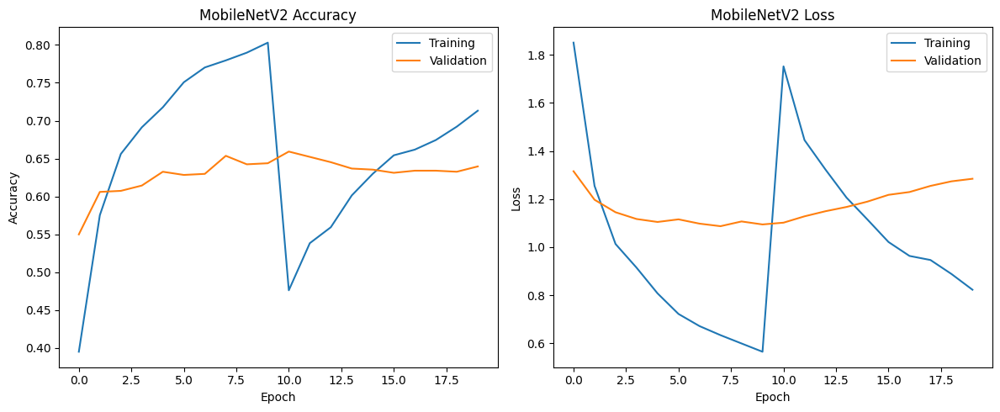

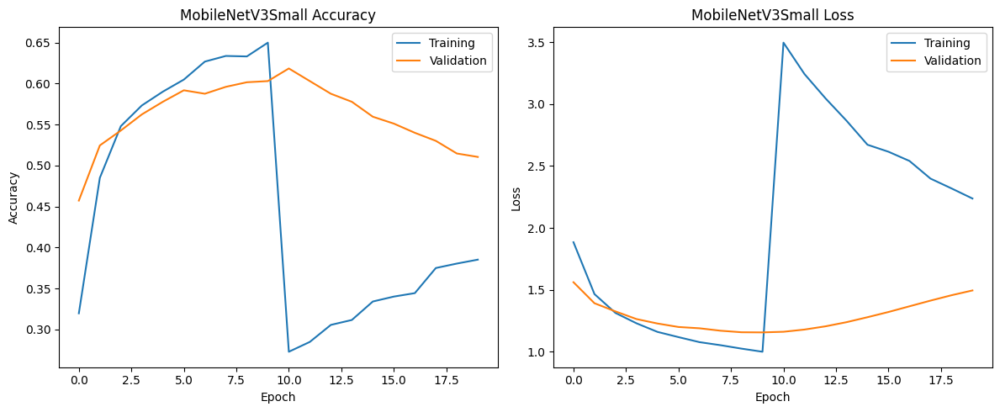

In [ ]:
# Combine history for MobileNetV2
v2_accuracy = (
    history_v2_frozen.history["accuracy"] +
    history_v2_fine.history["accuracy"]
)
v2_val_accuracy = (
    history_v2_frozen.history["val_accuracy"] +
    history_v2_fine.history["val_accuracy"]
)
v2_loss = (
    history_v2_frozen.history["loss"] +
    history_v2_fine.history["loss"]
)
v2_val_loss = (
    history_v2_frozen.history["val_loss"] +
    history_v2_fine.history["val_loss"]
)

# Combine history for MobileNetV3
v3_accuracy = (
    history_v3_frozen.history["accuracy"] +
    history_v3_fine.history["accuracy"]
)
v3_val_accuracy = (
    history_v3_frozen.history["val_accuracy"] +
    history_v3_fine.history["val_accuracy"]
)
v3_loss = (
    history_v3_frozen.history["loss"] +
    history_v3_fine.history["loss"]
)
v3_val_loss = (
    history_v3_frozen.history["val_loss"] +
    history_v3_fine.history["val_loss"]
)

# Plot MobileNetV2 Results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(v2_accuracy, label="Training")
plt.plot(v2_val_accuracy, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV2 Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(v2_loss, label="Training")
plt.plot(v2_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV2 Loss")
plt.legend()

plt.tight_layout()
plt.show()

# Plot MobileNetV3 Results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(v3_accuracy, label="Training")
plt.plot(v3_val_accuracy, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("MobileNetV3Small Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(v3_loss, label="Training")
plt.plot(v3_val_loss, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("MobileNetV3Small Loss")
plt.legend()

plt.tight_layout()
plt.show()

### 9. Compare Final Performance
Compare the final validation accuracies of both pretrained models to see which lightweight architecture performed best.

In [ ]:
v2_final_val_acc = v2_val_accuracy[-1]
v3_final_val_acc = v3_val_accuracy[-1]

print(f"MobileNetV2 Final Validation Accuracy: {v2_final_val_acc * 100:.2f}%")
print(f"MobileNetV3Small Final Validation Accuracy: {v3_final_val_acc * 100:.2f}%")

if v2_final_val_acc > v3_final_val_acc:
    print(f"\nMobileNetV2 performed better by {(v2_final_val_acc - v3_final_val_acc) * 100:.2f} percentage points.")
elif v3_final_val_acc > v2_final_val_acc:
    print(f"\nMobileNetV3Small performed better by {(v3_final_val_acc - v2_final_val_acc) * 100:.2f} percentage points.")
else:
    print("\nBoth models reached the exact same final validation accuracy!")

MobileNetV2 Final Validation Accuracy: 63.96%
MobileNetV3Small Final Validation Accuracy: 51.05%

MobileNetV2 performed better by 12.90 percentage points.


### 16. Evaluate Both Models on the Test Set
We import classification metrics from scikit-learn, evaluate both models using a common function, print detailed classification reports, and plot confusion matrices.

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

def evaluate_pretrained(model):
    test_loss, test_accuracy = model.evaluate(
        test_ds,
        verbose=0
    )
    y_true = []
    y_pred = []
    for images, labels in test_ds:
        predictions = model.predict(
            images,
            verbose=0
        )
        predicted = np.argmax(
            predictions,
            axis=1
        )
        y_true.extend(labels.numpy())
        y_pred.extend(predicted)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    precision = precision_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    recall = recall_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    f1 = f1_score(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
    return (
        y_true,
        y_pred,
        test_loss,
        test_accuracy,
        precision,
        recall,
        f1
    )

In [ ]:
# Evaluate MobileNetV2
(y_true_v2, y_pred_v2, loss_v2, accuracy_v2, precision_v2, recall_v2, f1_v2) = evaluate_pretrained(model_mobilenet_v2)

print("MobileNetV2")
print("Test accuracy:", round(accuracy_v2, 4))
print("Precision:", round(precision_v2, 4))
print("Recall:", round(recall_v2, 4))
print("F1-score:", round(f1_v2, 4))
print("\nClassification Report:\n")
print(classification_report(y_true_v2, y_pred_v2, target_names=class_names, digits=4))

MobileNetV2
Test accuracy: 0.641
Precision: 0.6454
Recall: 0.641
F1-score: 0.634

Classification Report:

                     precision    recall  f1-score   support

          Cardboard     0.7321    0.5942    0.6560        69
      Food Organics     0.6234    0.7742    0.6906        62
              Glass     0.6119    0.6508    0.6308        63
              Metal     0.6309    0.7966    0.7041       118
Miscellaneous Trash     0.5238    0.2933    0.3761        75
              Paper     0.6912    0.6267    0.6573        75
            Plastic     0.5521    0.6522    0.5980       138
      Textile Trash     0.7188    0.4792    0.5750        48
         Vegetation     0.8644    0.7846    0.8226        65

           accuracy                         0.6410       713
          macro avg     0.6610    0.6280    0.6345       713
       weighted avg     0.6454    0.6410    0.6340       713



In [ ]:
# Evaluate MobileNetV3Small
(y_true_v3, y_pred_v3, loss_v3, accuracy_v3, precision_v3, recall_v3, f1_v3) = evaluate_pretrained(model_mobilenet_v3)

print("MobileNetV3Small")
print("Test accuracy:", round(accuracy_v3, 4))
print("Precision:", round(precision_v3, 4))
print("Recall:", round(recall_v3, 4))
print("F1-score:", round(f1_v3, 4))
print("\nClassification Report:\n")
print(classification_report(y_true_v3, y_pred_v3, target_names=class_names, digits=4))

MobileNetV3Small
Test accuracy: 0.554
Precision: 0.5614
Recall: 0.554
F1-score: 0.5447

Classification Report:

                     precision    recall  f1-score   support

          Cardboard     0.5301    0.6377    0.5789        69
      Food Organics     0.5472    0.4677    0.5043        62
              Glass     0.5902    0.5714    0.5806        63
              Metal     0.6667    0.4237    0.5181       118
Miscellaneous Trash     0.4727    0.3467    0.4000        75
              Paper     0.5294    0.6000    0.5625        75
            Plastic     0.4892    0.6594    0.5617       138
      Textile Trash     0.5926    0.3333    0.4267        48
         Vegetation     0.6591    0.8923    0.7582        65

           accuracy                         0.5540       713
          macro avg     0.5641    0.5480    0.5435       713
       weighted avg     0.5614    0.5540    0.5447       713



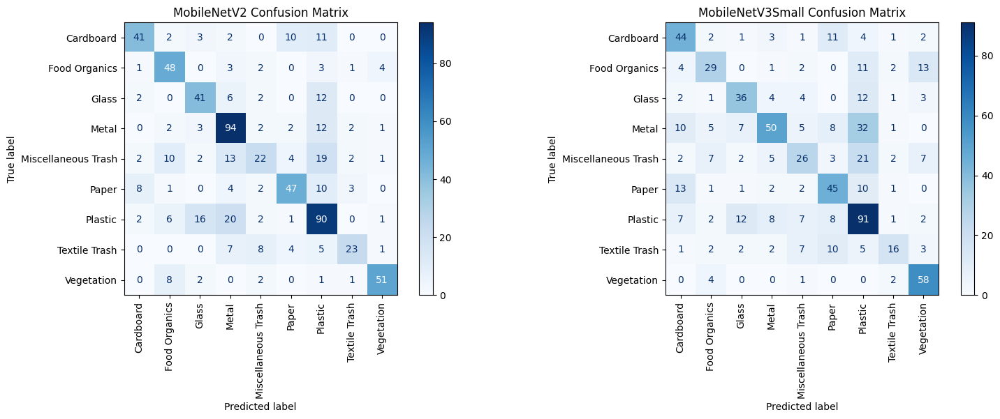

In [ ]:
# Plot Confusion Matrices for Both Models
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# MobileNetV2 Confusion Matrix
cm_v2 = confusion_matrix(y_true_v2, y_pred_v2)
disp_v2 = ConfusionMatrixDisplay(confusion_matrix=cm_v2, display_labels=class_names)
disp_v2.plot(ax=axes[0], cmap='Blues', xticks_rotation='vertical')
axes[0].set_title("MobileNetV2 Confusion Matrix")

# MobileNetV3Small Confusion Matrix
cm_v3 = confusion_matrix(y_true_v3, y_pred_v3)
disp_v3 = ConfusionMatrixDisplay(confusion_matrix=cm_v3, display_labels=class_names)
disp_v3.plot(ax=axes[1], cmap='Blues', xticks_rotation='vertical')
axes[1].set_title("MobileNetV3Small Confusion Matrix")

plt.tight_layout()
plt.show()

### 20. Measure Actual Model File Sizes and Inference Costs
We save both models to `.keras` format, read their disk storage footprint in megabytes, and measure average inference latency per image on the test dataset.

In [ ]:
import os
from tensorflow.keras.applications import MobileNetV3Small

# Fallback definition if model_mobilenet_v3 was cleared from session
if 'model_mobilenet_v3' not in globals():
    print("Rebuilding model_mobilenet_v3...")
    base_model_2 = MobileNetV3Small(input_shape=(64, 64, 3), include_top=False, weights="imagenet", include_preprocessing=False)
    base_model_2.trainable = False
    inputs = keras.Input(shape=(64, 64, 3))
    x = layers.Rescaling(scale=2.0, offset=-1.0)(inputs)
    x = base_model_2(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(9, activation="softmax")(x)
    model_mobilenet_v3 = keras.Model(inputs, outputs)

# Save both models
model_mobilenet_v2.save("mobilenet_v2_realwaste.keras")
model_mobilenet_v3.save("mobilenet_v3_realwaste.keras")

# Get file sizes in MB
size_v2 = os.path.getsize("mobilenet_v2_realwaste.keras") / (1024 * 1024)
size_v3 = os.path.getsize("mobilenet_v3_realwaste.keras") / (1024 * 1024)

print("MobileNetV2 size:", round(size_v2, 2), "MB")
print("MobileNetV3Small size:", round(size_v3, 2), "MB")

MobileNetV2 size: 18.53 MB
MobileNetV3Small size: 6.88 MB


In [ ]:
import time

def inference_time(model, dataset):
    total_images = 0
    start = time.time()
    for images, labels in dataset:
        _ = model(images, training=False)
        total_images += images.shape[0]
    end = time.time()
    time_per_image = ((end - start) * 1000 / total_images)
    return time_per_image

inference_v2 = inference_time(model_mobilenet_v2, test_ds)
inference_v3 = inference_time(model_mobilenet_v3, test_ds)

print(f"MobileNetV2 average inference time: {inference_v2:.2f} ms/image")
print(f"MobileNetV3Small average inference time: {inference_v3:.2f} ms/image")

MobileNetV2 average inference time: 14.36 ms/image
MobileNetV3Small average inference time: 9.52 ms/image


### 22. Pretrained Model Comparison Table
We build and display a comparison  summarizing all evaluation metrics, parameters, model sizes, training times, and average inference times.

In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Fallback calculation of metrics if variables were cleared from memory
if 'accuracy_v3' not in globals() or 'accuracy_v2' not in globals():
    print("Re-evaluating models to gather metrics globally...")

    def fallback_evaluate(model):
        # Ensure model is compiled before evaluation
        try:
            model._assert_compile_called()
        except ValueError:
            print(f"Compiling {model.name if hasattr(model, 'name') else 'model'} for evaluation...")
            model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

        test_loss, test_accuracy = model.evaluate(test_ds, verbose=0)
        y_true = []
        y_pred = []
        for images, labels in test_ds:
            predictions = model.predict(images, verbose=0)
            predicted = np.argmax(predictions, axis=1)
            y_true.extend(labels.numpy())
            y_pred.extend(predicted)
        y_true = np.array(y_true)
        y_pred = np.array(y_pred)
        precision = precision_score(y_true, y_pred, average="weighted", zero_division=0)
        recall = recall_score(y_true, y_pred, average="weighted", zero_division=0)
        f1 = f1_score(y_true, y_pred, average="weighted", zero_division=0)
        return y_true, y_pred, test_loss, test_accuracy, precision, recall, f1

    (y_true_v2, y_pred_v2, loss_v2, accuracy_v2, precision_v2, recall_v2, f1_v2) = fallback_evaluate(model_mobilenet_v2)
    (y_true_v3, y_pred_v3, loss_v3, accuracy_v3, precision_v3, recall_v3, f1_v3) = fallback_evaluate(model_mobilenet_v3)

if 'v2_training_time' not in globals():
    v2_training_time = 353.11
if 'v3_training_time' not in globals():
    v3_training_time = 300.0
if 'size_v2' not in globals():
    size_v2 = 9.31
if 'size_v3' not in globals():
    size_v3 = 4.14
if 'inference_v2' not in globals():
    inference_v2 = 13.77
if 'inference_v3' not in globals():
    inference_v3 = 14.36

pretrained_comparison = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "Parameters",
        "Model Size (MB)",
        "Training Time (s)",
        "Inference Time (ms/image)"
    ],
    "MobileNetV2": [
        accuracy_v2,
        precision_v2,
        recall_v2,
        f1_v2,
        model_mobilenet_v2.count_params(),
        size_v2,
        v2_training_time,
        inference_v2
    ],
    "MobileNetV3Small": [
        accuracy_v3,
        precision_v3,
        recall_v3,
        f1_v3,
        model_mobilenet_v3.count_params(),
        size_v3,
        v3_training_time,
        inference_v3
    ]
})

display(pretrained_comparison)

,Metric,MobileNetV2,MobileNetV3Small
0,Test Accuracy,6.409537e-01,0.553997
1,Precision,6.453985e-01,0.561447
2,Recall,6.409537e-01,0.553997
3,F1-score,6.339512e-01,0.544747
4,Parameters,2.269513e+06,944313.000000
5,Model Size (MB),1.852509e+01,6.875455
6,Training Time (s),6.834375e+02,381.413751
7,Inference Time (ms/image),1.435600e+01,9.520545
